# HVAC Control with Deep RL: Reward Design

This work studies the control of a building HVAC system with deep reinforcement learning. In the Sinergym environment (EnergyPlus simulation), an agent sets the heating and cooling setpoints of a 5-zone office every 15 minutes. The agent has to balance two opposite goals: lower HVAC electricity use and the comfort of the occupants.

The focus of the work is the **reward function**, since it is the only signal that defines the task for the agent. Three algorithms (SAC, PPO and TD3) with default hyperparameters are trained on different rewards and compared with **RBC5Zone**, the standard rule-based controller of Sinergym.

### Key results (test year, hot climate)

- **The reward matters more than the algorithm.** With the built-in Sinergym reward (R0) the agents use 10–42 % more energy than the baseline; with the calibrated reward (R2) the same algorithms use 12–14 % less energy at only 3–4 °C·h of discomfort a year.
- **Residual agents**, which correct the setpoints of a rule, save 21–24 %.
- **R2 ranks controllers exactly like the real KPI** (Spearman ρ = 1.0), while the built-in reward does not (ρ = −0.14).
- **Without retraining**, R2 agents also beat the baseline by 29–57 % in the mixed and cool climates.
- **A hand-tuned rule (−26 % energy) is still slightly better than every agent**; the remaining gap is overcooling in summer.

### Contents

1. Environment (EDA)
2. Baselines
3. Reward function
4. Training
5. Agent comparison on test
6. Stress tests
7. Agent behaviour
8. Conclusions and limitations

In [1]:
%load_ext autoreload
%autoreload 2
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hvac_rl import building, eda
from hvac_rl.baselines import POLICY_LABELS as LABELS, load_policies, r1_score
from hvac_rl.envs import ENV_IDS, ZONES, CORE_ZONE, STEP_HOURS, comfort_bounds, zone_temp_col
from hvac_rl.evaluate import kpis, zone_discomfort
from hvac_rl.rewards import R1Config, r1_from_log, P_REF_W, DT_REF_C

pd.set_option("display.precision", 2)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TEXT, TEXT_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2, "axes.titlesize": 11, "axes.titlecolor": TEXT,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 1.6, "legend.frameon": False, "legend.labelcolor": TEXT_2,
    "axes.prop_cycle": plt.cycler(color=SERIES),
})
fmt = lambda x: f"{x:,.0f}"

## 1. Environment (EDA)

This section describes the simulation environment: the building, the occupancy schedule, the observation and action spaces, and the climates. The aim is to find where energy can be saved before any agent is trained.

### 1.1 Building and HVAC system

In [2]:
zones = building.zones_table()
zones

,orientation,area_m2,volume_m3,people_max,lights_W_m2,equipment_W_m2
zone,,,,,,
SPACE1-1,SW,98.12,239.25,11,16.14,10.76
SPACE2-1,SE,42.37,103.31,5,16.14,10.76
SPACE3-1,NE,98.12,239.25,11,16.14,10.76
SPACE4-1,NW,42.37,103.31,5,16.14,10.76
SPACE5-1,core,183.60,447.68,20,16.14,10.76


In [3]:
pd.Series(building.hvac_summary(), name="value").to_frame()

,value
air_loop,VAV Sys 1
cooling,"DX two-speed, COP 3.0/4.2 (high/low)"
heating,electric: central coil + reheat coil in each V...
terminals,AirTerminal:SingleDuct:VAV:Reheat x5
economizer,"FixedDryBulb, 4.0-19.0 degC"
supply_fan_always_on,True
timestep_min,15


The building is a one-storey office of about 460 m² with four perimeter zones and a large core zone (SPACE5-1), which takes 40 % of the floor area. One VAV system serves all zones, heating is fully electric, and the supply fan runs 24/7. The controller sets **one pair of setpoints for the whole building**, not for each zone separately.

### 1.2 Occupancy

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


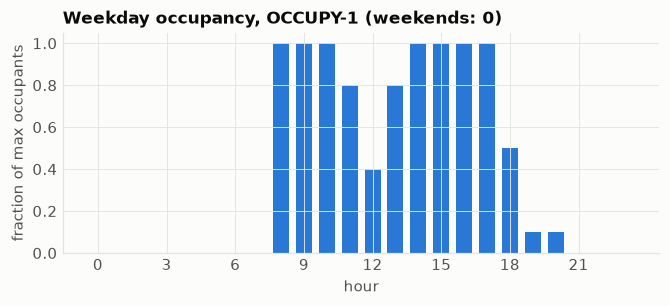

In [4]:
occ = building.schedule_profile("OCCUPY-1", "WeekDays")
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.bar(occ.index, occ.values, width=0.7, color=SERIES[0])
ax.set(xlabel="hour", ylabel="fraction of max occupants", xticks=range(0, 24, 3),
       title="Weekday occupancy, OCCUPY-1 (weekends: 0)");

People are present **only on weekdays from 08:00 to 21:00**, which is about 39 % of all time steps; on weekends the building is empty. Conditioning an empty building brings no benefit, so this schedule is the **main source of possible savings**.

### 1.3 Observation and action

In [5]:
eda.observation_spec()

,feature,type,source
0,month,time,
1,day_of_month,time,
2,hour,time,
3,outdoor_temperature,E+ variable,Site Outdoor Air DryBulb Temperature [Environm...
4,outdoor_humidity,E+ variable,Site Outdoor Air Relative Humidity [Environment]
5,wind_speed,E+ variable,Site Wind Speed [Environment]
6,wind_direction,E+ variable,Site Wind Direction [Environment]
7,diffuse_solar_radiation,E+ variable,Site Diffuse Solar Radiation Rate per Area [En...
8,direct_solar_radiation,E+ variable,Site Direct Solar Radiation Rate per Area [Env...
9,air_temperature,E+ variable,Zone Air Temperature [SPACE5-1]


The observation contains 17 values: time, weather, core-zone temperature, occupancy, current setpoints and HVAC power. The perimeter zones and the day of the week are not observed. The setpoint range is kept wide on purpose (heating 12–23.25 °C, cooling 23.25–30 °C): in this case **only the reward prevents the agent from simply switching the HVAC off**, and the effect of the reward is seen directly.

### 1.4 Climates and data split

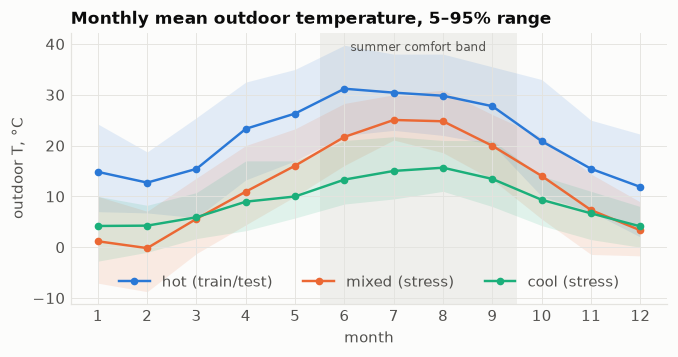

In [6]:
runs = eda.load_runs()
climates = {"hot (train/test)": runs[("test", "rbc5zone")],
            "mixed (stress)": runs[("stress_mixed", "rbc5zone")],
            "cool (stress)": runs[("stress_cool", "rbc5zone")]}

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.axvspan(5.5, 9.5, color=GRID, alpha=0.5, lw=0)
ax.text(7.5, 0.97, "summer comfort band", transform=ax.get_xaxis_transform(),
        ha="center", va="top", color=TEXT_2, fontsize=8)
for (label, df), c in zip(climates.items(), SERIES):
    m = df.groupby("month")["outdoor_temperature"]
    ax.plot(m.mean(), color=c, marker="o", ms=4, label=label)
    ax.fill_between(m.mean().index, m.quantile(0.05), m.quantile(0.95), color=c, alpha=0.12, lw=0)
ax.set(xlabel="month", ylabel="outdoor T, °C", xticks=range(1, 13),
       title="Monthly mean outdoor temperature, 5–95% range")
ax.legend(loc="lower center", ncol=3);

In [7]:
noise = runs[("train", "rbc5zone")]["outdoor_temperature"] - runs[("test", "rbc5zone")]["outdoor_temperature"]
print(f"stochastic - deterministic outdoor T: mean {noise.mean():.2f} °C, std {noise.std():.2f} °C")
pd.Series(ENV_IDS, name="env_id").to_frame()

stochastic - deterministic outdoor T: mean -0.05 °C, std 0.98 °C


,env_id
train,Eplus-5zone-hot-continuous-stochastic-v1
val,Eplus-5zone-hot-continuous-stochastic-v1
test,Eplus-5zone-hot-continuous-v1
stress_mixed,Eplus-5zone-mixed-continuous-v1
stress_cool,Eplus-5zone-cool-continuous-v1


Agents are trained on the hot climate with random weather noise (about 1 °C) and validated on the same climate with a different noise seed. The final test is the deterministic hot year. The **mixed and cool climates are used only as stress tests** and never for training. No parameter is selected on the test year.

### 1.5 Simple policies: energy vs comfort

In [8]:
kpi = eda.kpi_table(runs)
kpi[["energy_kwh", "power_mean_kw", "power_p95_kw", "power_peak_kw", "discomfort_occ_Ch", "frac_occ_outside",
     "discomfort_unocc_Ch", "discomfort_occ_Ch_allzones", "reward_sum", "reward_energy_sum", "reward_comfort_sum"]]

energy_kwh  power_mean_kw  power_p95_kw  \
split        policy                                                 
stress_cool  off_12_30       2434.51           0.28          1.08   
             rbc5zone       18032.71           2.06          5.22   
stress_mixed off_12_30       5764.24           0.66          2.15   
             rbc5zone       20587.60           2.35          6.73   
test         fixed_21_24    21235.61           2.43          6.58   
             occ_setback    14623.95           1.67          6.59   
             off_12_30       7406.74           0.85          2.55   
             rbc5zone       18740.82           2.14          5.84   
             tight_2325     33994.09           3.88          7.55   
train        rbc5zone       18787.76           2.15          5.82   

                          power_peak_kw  discomfort_occ_Ch  frac_occ_outside  \
split        policy                                                            
stress_cool  off_12_30             3.36           11268.96              0.90   
             rbc5zone             11.94               0.26              0.03   
stress_mixed off_12_30             7.40           11056.14              0.88   
             rbc5zone             19.82               0.09              0.02   
test         fixed_21_24           9.68             999.56              0.61   
             occ_setback           9.58             983.89              0.60   
             off_12_30             4.01           14230.35              0.95   
             rbc5zone              8.38               0.05              0.02   
             tight_2325           10.45               0.00              0.00   
train        rbc5zone              8.44               0.05              0.02   

                          discomfort_unocc_Ch  discomfort_occ_Ch_allzones  \
split        policy                                                         
stress_cool  off_12_30                5069.68                    10152.05   
             rbc5zone                    0.63                      269.62   
stress_mixed off_12_30                4636.91                    10342.56   
             rbc5zone                    1.43                      138.05   
test         fixed_21_24              1306.29                     1172.03   
             occ_setback              2226.02                     1221.22   
             off_12_30                1815.64                    14456.98   
             rbc5zone                    0.22                      250.57   
             tight_2325                  0.00                      242.73   
train        rbc5zone                    0.24                      249.70   

                          reward_sum  reward_energy_sum  reward_comfort_sum  
split        policy                                                          
stress_cool  off_12_30     -33161.42            -484.15           -32677.27  
             rbc5zone       -3609.16           -3607.39               -1.78  
stress_mixed off_12_30     -32536.39           -1150.29           -31386.11  
             rbc5zone       -4121.73           -4118.71               -3.02  
test         fixed_21_24    -8860.83           -4249.12            -4611.71  
             occ_setback    -9339.68           -2919.86            -6419.82  
             off_12_30     -33575.09           -1483.11           -32091.99  
             rbc5zone       -3750.38           -3749.82               -0.55  
             tight_2325     -6799.11           -6799.11                0.00  
train        rbc5zone       -3759.94           -3759.34               -0.60

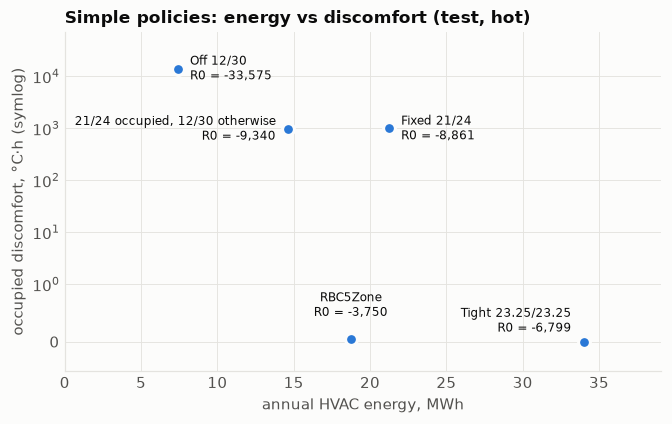

In [9]:
test_kpi = kpi.xs("test")
offsets = {"occ_setback": (-8, 0, "right"), "rbc5zone": (0, 22, "center"), "tight_2325": (-8, 14, "right")}

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(test_kpi["energy_kwh"] / 1e3, test_kpi["discomfort_occ_Ch"], s=60, color=SERIES[0],
           edgecolor=SURFACE, linewidth=2, zorder=3)
for name, r in test_kpi.iterrows():
    dx, dy, ha = offsets.get(name, (8, 0, "left"))
    ax.annotate(f"{LABELS[name]}\nR0 = {fmt(r['reward_sum'])}", (r["energy_kwh"] / 1e3, r["discomfort_occ_Ch"]),
                xytext=(dx, dy), textcoords="offset points", va="center", ha=ha, fontsize=8, color=TEXT)
ax.set_yscale("symlog", linthresh=1)
ax.set(xlabel="annual HVAC energy, MWh", ylabel="occupied discomfort, °C·h (symlog)",
       xlim=(0, test_kpi["energy_kwh"].max() / 1e3 * 1.15), ylim=(-0.5, test_kpi["discomfort_occ_Ch"].max() * 5),
       title="Simple policies: energy vs discomfort (test, hot)");

The plot places several simple policies by annual energy and occupied discomfort. Switching the HVAC off still costs 7.4 MWh, because the supply fan always runs, while the building is uncomfortable most of the time. RBC5Zone keeps the core comfortable but uses **18.7 MWh**. **No fixed pair of setpoints is comfortable all year**, since the winter (20–23.5 °C) and summer (23–26 °C) bands overlap only at 23–23.5 °C.

### 1.6 R0 decomposition

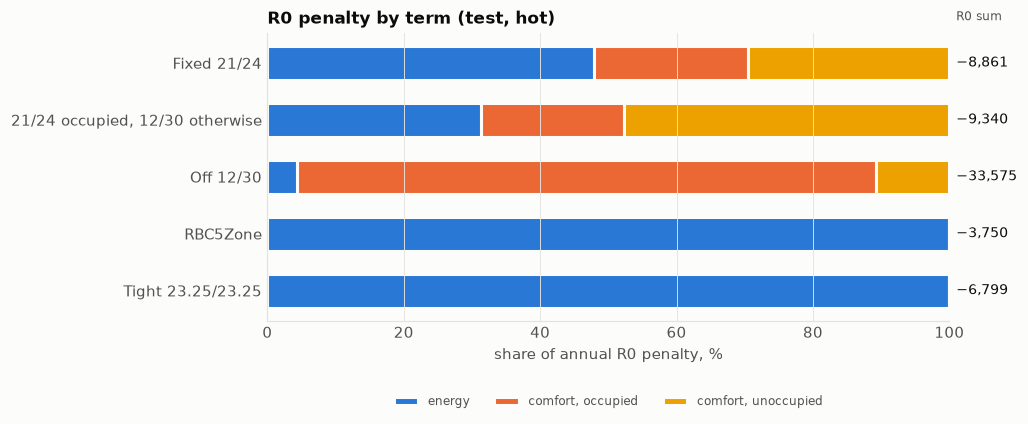

In [10]:
parts = pd.DataFrame({
    p: {"energy": -d["energy_term"].sum(),
        "comfort, occupied": -d.loc[d.occupied, "comfort_term"].sum(),
        "comfort, unoccupied": -d.loc[~d.occupied, "comfort_term"].sum()}
    for p, d in ((p, runs[("test", p)]) for p in test_kpi.index)
}).T
share = 100 * parts.div(parts.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8, 3.4))
y, left = np.arange(len(share)), np.zeros(len(share))
for col, c in zip(share.columns, [SERIES[0], SERIES[1], SERIES[3]]):
    ax.barh(y, share[col], left=left, color=c, label=col, height=0.6, edgecolor=SURFACE, linewidth=2)
    left += share[col].values
for yi, total in zip(y, parts.sum(axis=1)):
    ax.text(101, yi, f"−{fmt(total)}", va="center", fontsize=9, color=TEXT)
ax.text(101, -0.75, "R0 sum", fontsize=8, color=TEXT_2)
ax.set_yticks(y, [LABELS[p] for p in share.index])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set(xlim=(0, 100), xlabel="share of annual R0 penalty, %", title="R0 penalty by term (test, hot)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8);

**The built-in reward R0 is almost entirely about comfort, and it penalises discomfort also when the building is empty.** For the policy that relaxes the setpoints in the empty building, almost half of the R0 penalty comes from unoccupied hours. As a result, R0 penalises exactly the cheapest way to save energy.

### 1.7 Comfort by zone

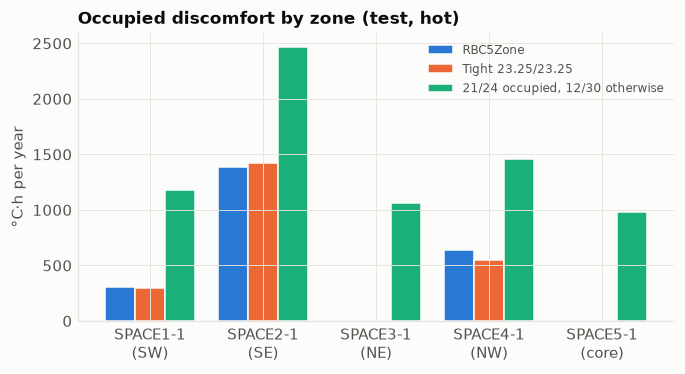

In [11]:
policies = ["rbc5zone", "tight_2325", "occ_setback"]
x, w = np.arange(len(ZONES)), 0.8 / len(policies)

fig, ax = plt.subplots(figsize=(7, 3.4))
for i, (p, c) in enumerate(zip(policies, SERIES)):
    zd = zone_discomfort(runs[("test", p)])[ZONES]
    ax.bar(x + (i - (len(policies) - 1) / 2) * w, zd.values, width=w, color=c, label=LABELS[p],
           edgecolor=SURFACE, linewidth=1)
ax.set_xticks(x, [f"{z}\n({zones.loc[z, 'orientation']})" for z in ZONES])
ax.set(ylabel="°C·h per year", title="Occupied discomfort by zone (test, hot)")
ax.legend(fontsize=8);

The perimeter zones overheat at any setpoints (the SE zone accumulates about 1 400 °C·h even with RBC5Zone). This is a limit of the HVAC system, not of the controller. The core zone can be kept in band, therefore **comfort is measured in the core zone** in the rewards and KPIs.

### 1.8 Power profile and scale

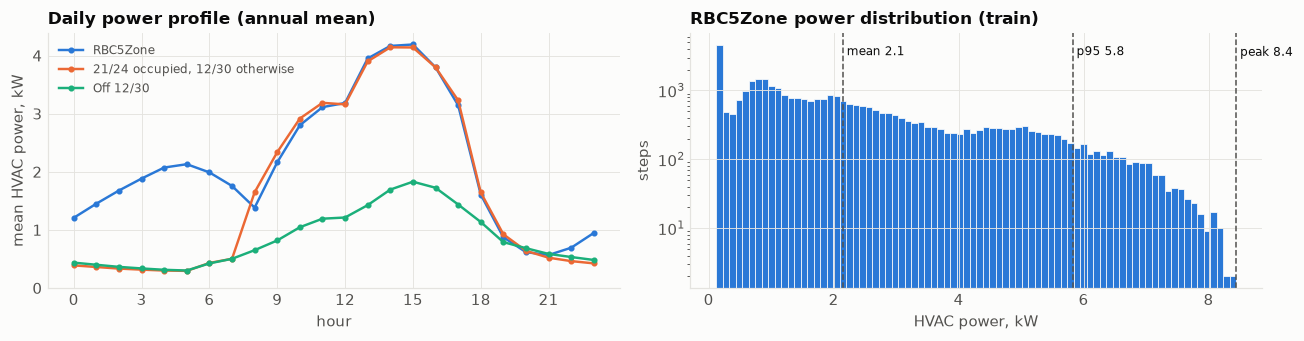

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.2))
for p, c in zip(["rbc5zone", "occ_setback", "off_12_30"], SERIES):
    prof = runs[("test", p)].groupby("hour")["power_kw"].mean()
    ax1.plot(prof, color=c, marker="o", ms=3, label=LABELS[p])
ax1.set(xlabel="hour", ylabel="mean HVAC power, kW", xticks=range(0, 24, 3), ylim=(0, None),
        title="Daily power profile (annual mean)")
ax1.legend(fontsize=8)

pw = runs[("train", "rbc5zone")]["power_kw"]
ax2.hist(pw, bins=80, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
for q, lab in [(pw.mean(), "mean"), (pw.quantile(0.95), "p95"), (pw.max(), "peak")]:
    ax2.axvline(q, color=TEXT_2, lw=1, ls="--")
    ax2.text(q, 0.95, f" {lab} {q:.1f}", transform=ax2.get_xaxis_transform(), va="top", fontsize=8, color=TEXT)
ax2.set(xlabel="HVAC power, kW", ylabel="steps", yscale="log", title="RBC5Zone power distribution (train)")
fig.tight_layout()

RBC5Zone draws 2.1 kW on average and peaks near 10 kW. The value **2.15 kW is used as the energy scale**, so the energy term of the rewards is of order 1 per step.

### 1.9 Typical days

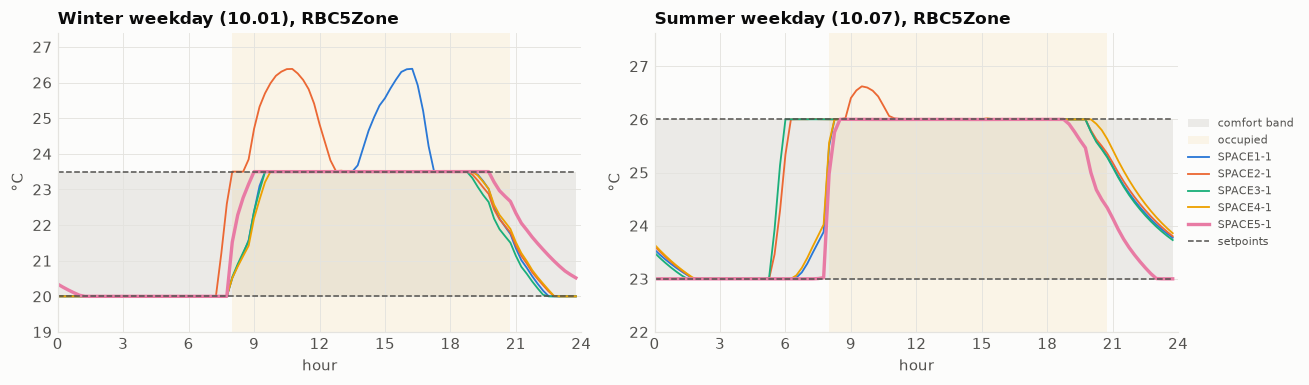

In [13]:
def pick_weekday(df, month):
    has_people = df[df.month == month].groupby("day_of_month")["people_occupant"].max() > 0
    return int(has_people[has_people & (has_people.index >= 10)].index[0])


def plot_day(ax, df, month, title, name):
    day = pick_weekday(df, month)
    d = df[(df.month == month) & (df.day_of_month == day)].reset_index(drop=True)
    t = np.arange(len(d)) * STEP_HOURS
    lo, hi = comfort_bounds(d["month"])
    temps = d[[zone_temp_col(z) for z in ZONES]]
    ax.fill_between(t, lo, hi, color=GRID, alpha=0.7, lw=0, label="comfort band")
    ax.fill_between(t, 0, 50, where=d["occupied"], color=SERIES[3], alpha=0.08, lw=0, label="occupied")
    for z, c in zip(ZONES, SERIES):
        ax.plot(t, d[zone_temp_col(z)], color=c, lw=2.2 if z == CORE_ZONE else 1.2, label=z)
    ax.step(t, d["a_heat"], color=TEXT_2, lw=1, ls="--", where="post", label="setpoints")
    ax.step(t, d["a_cool"], color=TEXT_2, lw=1, ls="--", where="post")
    ax.set(xlabel="hour", ylabel="°C", xticks=range(0, 25, 3), xlim=(0, 24),
           ylim=(min(temps.min().min(), lo.min()) - 1, max(temps.max().max(), hi.max()) + 1),
           title=f"{title} ({day:02d}.{month:02d}), {name}")


def plot_days(df, name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    plot_day(axes[0], df, 1, "Winter weekday", name)
    plot_day(axes[1], df, 7, "Summer weekday", name)
    axes[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.tight_layout()


plot_days(runs[("test", "rbc5zone")], "RBC5Zone")

RBC5Zone keeps the core inside the comfort band day and night, **including nights and weekends when the building is empty**.

## 2. Baselines

This section defines the controllers used for comparison.

| Controller | Role | Definition |
|---|---|---|
| **RBC5Zone** | **baseline** | Sinergym's standard rule-based controller: winter 20/23.5 °C, summer 23/26 °C, 24/7, no occupancy logic |
| Fixed 21/24 | naive reference | constant thermostat setpoints all year |
| Tuned RBC | **experimental reference, not a baseline** | seasonal RBC + night/weekend setback, grid-searched on train by R1 (w=0.5); shows how far a simple hand-tuned rule can go |

RBC5Zone is the main baseline, as the standard controller of the environment. The tuned RBC is not a baseline: it is an upper reference that shows the result of a simple rule tuned for this building.

### 2.1 Tuned RBC (experimental reference)

In [14]:
tuned = load_policies(eda.BASELINES_DIR / "tuned_rbc.json")
pd.DataFrame({k: vars(v) for k, v in tuned.items()}).T

,winter,summer,winter_setback,summer_setback
tuned_rbc_w0.3,"(18.0, 23.25)","(18.0, 26.0)","(12.0, 30.0)","(12.0, 30.0)"
tuned_rbc_w0.5,"(18.0, 23.25)","(18.0, 26.0)","(12.0, 30.0)","(12.0, 30.0)"
tuned_rbc_w0.7,"(18.0, 23.25)","(18.0, 26.0)","(12.0, 30.0)","(12.0, 30.0)"


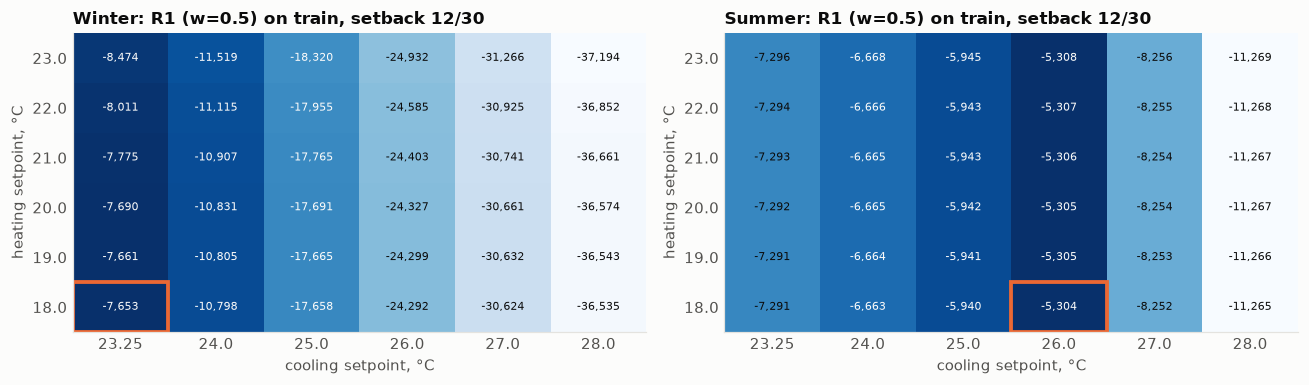

In [15]:
grid = pd.read_csv(eda.BASELINES_DIR / "rbc_grid_train.csv")
grid = grid[grid.setback_heat == 12].assign(score=lambda g: r1_score(g, R1Config(w=0.5)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, season in zip(axes, ["winter", "summer"]):
    m = grid[grid.season == season].pivot(index="heat", columns="cool", values="score")
    ax.imshow(m.values, cmap="Blues", aspect="auto", origin="lower")
    ax.set_xticks(range(len(m.columns)), m.columns)
    ax.set_yticks(range(len(m.index)), m.index)
    i, j = np.unravel_index(np.nanargmax(m.values), m.shape)
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=SERIES[1], lw=2.5))
    for (yi, xi), v in np.ndenumerate(m.values):
        ax.text(xi, yi, fmt(v), ha="center", va="center", fontsize=7,
                color=SURFACE if v > np.nanmedian(m.values) else TEXT)
    ax.grid(False)
    ax.set(xlabel="cooling setpoint, °C", ylabel="heating setpoint, °C",
           title=f"{season.capitalize()}: R1 (w=0.5) on train, setback 12/30")
fig.tight_layout()

The tuned RBC is obtained by a grid search over winter and summer setpoint pairs on the training year, with R1 (w = 0.5) as the criterion. The heat maps show the score of each pair, and the best pair is marked. The selected rule is simple: 18/23.25 °C in winter and 18/26 °C in summer during occupied hours, and 12/30 °C (practically off) in the empty building. The rule is the same for every weight w, because the setback in the empty building outweighs all other effects.

### 2.2 Baseline KPIs

In [16]:
base = eda.load_runs(eda.BASELINES_DIR)
names = ["fixed_21_24", "rbc5zone", "tuned_rbc_w0.5"]
rows = {}
for (split, name), d in base.items():
    if name in names:
        k = kpis(d, building.zone_areas())
        rows[(split, LABELS[name])] = {
            "energy_MWh": k["energy_kwh"] / 1e3, "peak_kW": k["power_peak_kw"],
            "discomfort_occ_Ch": k["discomfort_occ_Ch"], "frac_occ_outside": k["frac_occ_outside"],
            "discomfort_all_zones_Ch": k["discomfort_occ_Ch_allzones"],
            "R0": k["reward_sum"], "R1 (w=0.5)": r1_from_log(d, R1Config()).r1.sum()}
order = ["train", "val", "test", "stress_mixed", "stress_cool"]
pd.DataFrame(rows).T.loc[[(s, LABELS[n]) for s in order for n in names]]

energy_MWh  peak_kW  discomfort_occ_Ch  \
train        Fixed 21/24       21.30    10.83             999.03   
             RBC5Zone          18.79     8.44               0.05   
             Tuned RBC         13.86     8.69               6.71   
val          Fixed 21/24       21.50    10.15             999.16   
             RBC5Zone          18.93     8.80               0.06   
             Tuned RBC         14.03     9.13               6.65   
test         Fixed 21/24       21.24     9.68             999.56   
             RBC5Zone          18.74     8.38               0.05   
             Tuned RBC         13.85     8.65               6.25   
stress_mixed Fixed 21/24       23.56    19.82             925.13   
             RBC5Zone          20.59    19.82               0.09   
             Tuned RBC          9.04    19.07              55.32   
stress_cool  Fixed 21/24       19.39    11.94             953.81   
             RBC5Zone          18.03    11.94               0.26   
             Tuned RBC          4.53     9.90              46.47   

                          frac_occ_outside  discomfort_all_zones_Ch        R0  \
train        Fixed 21/24              0.61                  1170.61  -8880.92   
             RBC5Zone                 0.02                   249.70  -3759.94   
             Tuned RBC                0.02                   328.78  -6925.85   
val          Fixed 21/24              0.61                  1172.90  -8873.42   
             RBC5Zone                 0.02                   252.07  -3788.68   
             Tuned RBC                0.02                   330.78  -6943.38   
test         Fixed 21/24              0.61                  1172.03  -8860.83   
             RBC5Zone                 0.02                   250.57  -3750.38   
             Tuned RBC                0.02                   328.47  -6881.65   
stress_mixed Fixed 21/24              0.57                   922.44 -10214.12   
             RBC5Zone                 0.02                   138.05  -4121.73   
             Tuned RBC                0.03                   350.04 -12074.63   
stress_cool  Fixed 21/24              0.59                  1095.90 -10630.24   
             RBC5Zone                 0.03                   269.62  -3609.16   
             Tuned RBC                0.02                   425.52 -12303.71   

                          R1 (w=0.5)  
train        Fixed 21/24   -23817.66  
             RBC5Zone      -17485.58  
             Tuned RBC     -12957.31  
val          Fixed 21/24   -24003.33  
             RBC5Zone      -17619.58  
             Tuned RBC     -13117.12  
test         Fixed 21/24   -23761.59  
             RBC5Zone      -17441.32  
             Tuned RBC     -12950.68  
stress_mixed Fixed 21/24   -25627.88  
             RBC5Zone      -19157.21  
             Tuned RBC      -8637.12  
stress_cool  Fixed 21/24   -21859.88  
             RBC5Zone      -16779.64  
             Tuned RBC      -4408.46

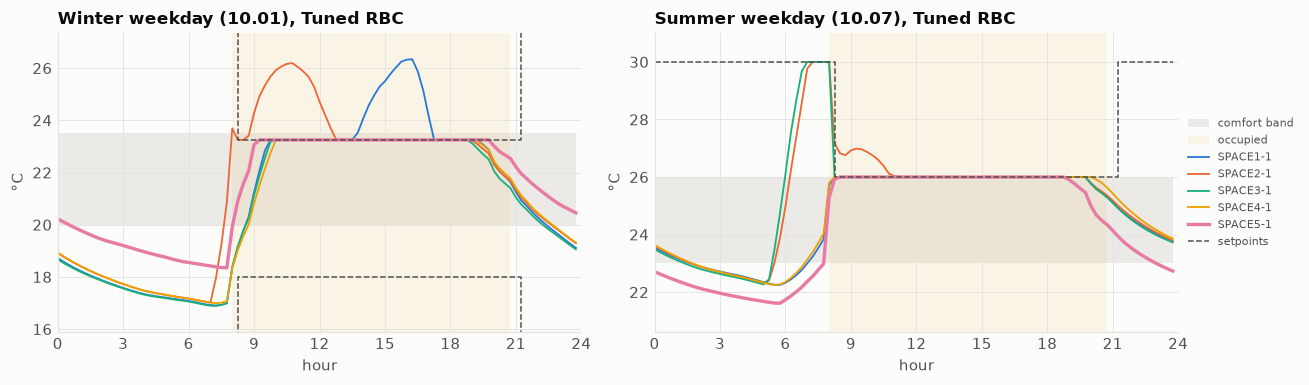

In [17]:
plot_days(base[("test", "tuned_rbc_w0.5")], "Tuned RBC")

**The tuned RBC uses 26 % less energy than RBC5Zone (13.9 vs 18.7 MWh) at only about 6 °C·h of discomfort a year.** Almost all of the saving comes from not conditioning the empty building. It serves as a reference for what a well-tuned rule can achieve.

## 3. Reward function

This section is the central part of the work. It defines the rewards, compares the scales of their terms and checks whether each reward ranks controllers in the same way as the real KPIs.

### 3.1 R1 definition

R1 consists of three terms: energy (HVAC power divided by a reference power), comfort (deviation of the core temperature from the band, counted only in occupied hours) and a small penalty on the change of the action, which discourages oscillating setpoints.

$$r_t = -\Big[\, w\,\frac{P_t}{P_{ref}} + (1-w)\,\mathbb{1}[\text{occupied}]\,\frac{\Delta T_t}{\Delta T_{ref}} + \lambda\,\tfrac12\Big(\frac{|\Delta a^{heat}_t|}{11.25} + \frac{|\Delta a^{cool}_t|}{6.75}\Big)\Big]$$

$P_{ref}$ = 2150 W, $\Delta T_{ref}$ = 0.5 °C, $\lambda$ = 0.1, $w \in \{0.3, 0.5, 0.7\}$

In [18]:
pd.DataFrame({w: {"kWh per 1 °C·h": (1 - w) / w * P_REF_W / 1e3 / DT_REF_C} for w in [0.3, 0.5, 0.7]}).T

,kWh per 1 °C·h
0.3,10.03
0.5,4.30
0.7,1.84


The weight w sets the exchange rate between energy and comfort. **At w = 0.5, one °C·h of discomfort is worth only 4.3 kWh**, which later proved far too cheap (see 3.6).

### 3.2 Term scales: R0 vs R1

In [19]:
controllers = {**{p: runs[("test", p)] for p in ["off_12_30", "occ_setback", "tight_2325"]},
               **{n: base[("test", n)] for n in names}}
scale = pd.DataFrame({
    LABELS[n]: {
        "R0 energy": -d["energy_term"].mean(), "R0 comfort": -d["comfort_term"].mean(),
        **{f"R1 {k}": -r1_from_log(d, R1Config())[f"r1_{k}"].mean() for k in ["energy", "comfort", "smooth"]}}
    for n, d in controllers.items()}).T.abs()
scale.style.format("{:.3f}")

,R0 energy,R0 comfort,R1 energy,R1 comfort,R1 smooth
Off 12/30,0.042,0.916,0.197,1.624,0.000
"21/24 occupied, 12/30 otherwise",0.083,0.183,0.388,0.112,0.001
Tight 23.25/23.25,0.194,0.000,0.903,0.000,0.000
Fixed 21/24,0.121,0.132,0.564,0.114,0.000
RBC5Zone,0.107,0.000,0.498,0.000,0.000
Tuned RBC,0.079,0.117,0.368,0.001,0.001


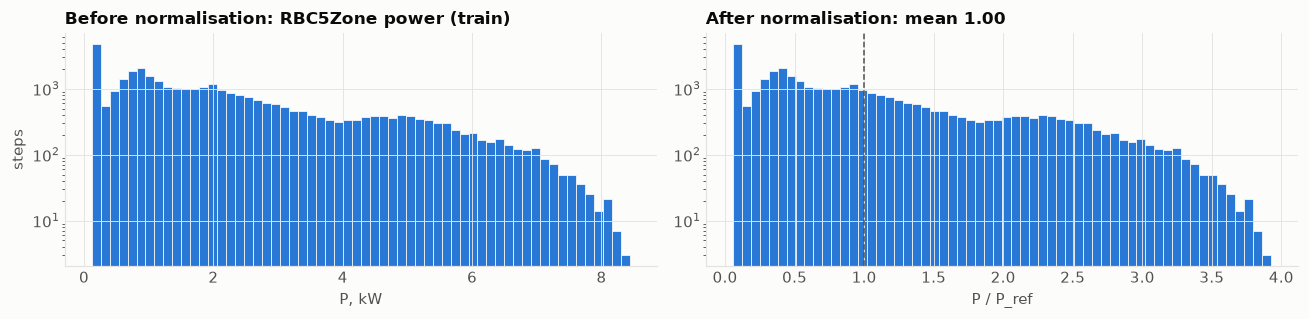

In [20]:
e = r1_from_log(base[("train", "rbc5zone")], R1Config())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))
ax1.hist(base[("train", "rbc5zone")]["power_kw"], bins=60, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
ax1.set(xlabel="P, kW", ylabel="steps", yscale="log", title="Before normalisation: RBC5Zone power (train)")
ax2.hist(e["e_norm"], bins=60, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
ax2.axvline(e["e_norm"].mean(), color=TEXT_2, ls="--", lw=1)
ax2.set(xlabel="P / P_ref", yscale="log", title=f"After normalisation: mean {e['e_norm'].mean():.2f}")
fig.tight_layout()

The table compares the mean size of each term per step; the histograms show the power before and after normalisation. In R0, one step of energy costs about 0.1, while 1 °C outside the band costs 0.5, so **R0 is mainly a comfort reward**. After normalisation the R1 terms are of comparable size, so neither term dominates by construction.

### 3.3 Reward vs KPI ranking (baselines)

In [21]:
rank = pd.DataFrame({LABELS[n]: {
    "energy_MWh": d["energy_kwh"].sum() / 1e3,
    "discomfort_Ch": d.loc[d.occupied, f"viol_{CORE_ZONE}"].sum() * STEP_HOURS,
    "R0": d["reward"].sum(),
    **{f"R1 w={w}": r1_from_log(d, R1Config(w=w)).r1.sum() for w in [0.3, 0.5, 0.7]}}
    for n, d in controllers.items()}).T
rank.join(rank[["R0", "R1 w=0.3", "R1 w=0.5", "R1 w=0.7"]].rank(ascending=False).astype(int).add_prefix("rank "))

,energy_MWh,discomfort_Ch,R0,R1 w=0.3,R1 w=0.5,R1 w=0.7,rank R0,rank R1 w=0.3,rank R1 w=0.5,rank R1 w=0.7
Off 12/30,7.41,14230.35,-33575.09,-83828.88,-63819.59,-43810.29,6,6,6,5
"21/24 occupied, 12/30 otherwise",14.62,983.89,-9339.68,-13702.28,-17560.36,-21418.44,5,3,3,2
Tight 23.25/23.25,33.99,0.00,-6799.11,-18974.25,-31623.75,-44273.25,2,5,5,6
Fixed 21/24,21.24,999.56,-8860.83,-17455.54,-23761.59,-30067.63,4,4,4,4
RBC5Zone,18.74,0.05,-3750.38,-10464.99,-17441.32,-24417.65,1,2,2,3
Tuned RBC,13.85,6.25,-6881.65,-7805.01,-12950.68,-18096.34,3,1,1,1


Before training, the rewards are checked on simple controllers. **R0 ranks RBC5Zone first and the tuned RBC only third**, below a policy that holds 23.25 °C all year and uses 34 MWh. R1 ranks the tuned RBC first. An agent trained on R0 is therefore rewarded for wasting energy.

### 3.4 Agents trained on R0 (test)

In [22]:
from hvac_rl import runs as rr
from hvac_rl.evaluate import policy_metrics

R0_RUNS = {"ppo_r0_s1": "PPO (R0)", "sac_r0_s1": "SAC (R0)", "td3_r0_s1": "TD3 (R0)"}
BASE_RUNS = {"rbc5zone": "RBC5Zone", "tuned_rbc_w0.5": "Tuned RBC"}


def compare(split):
    rows = {lab: policy_metrics(base[(split, n)]) for n, lab in BASE_RUNS.items()}
    rows.update({lab: policy_metrics(rr.load_eval_log(r, split)) for r, lab in R0_RUNS.items()})
    t = pd.DataFrame(rows).T
    t = t.assign(energy_MWh=t.energy_kwh / 1e3, energy_occ_MWh=t.energy_occ_kwh / 1e3,
                 energy_unocc_MWh=t.energy_unocc_kwh / 1e3)
    t["rank R0"] = t["R0"].rank(ascending=False).astype(int)
    t["rank R1 (w=0.5)"] = t["R1_w0.5"].rank(ascending=False).astype(int)
    return t[["energy_MWh", "energy_occ_MWh", "energy_unocc_MWh", "power_peak_kw", "discomfort_occ_Ch",
              "discomfort_occ_hot_Ch", "discomfort_unocc_Ch", "frac_occ_bound_violating",
              "R0", "R1_w0.5", "rank R0", "rank R1 (w=0.5)"]]


r0_test = compare("test")
r0_test

,energy_MWh,energy_occ_MWh,energy_unocc_MWh,power_peak_kw,discomfort_occ_Ch,discomfort_occ_hot_Ch,discomfort_unocc_Ch,frac_occ_bound_violating,R0,R1_w0.5,rank R0,rank R1 (w=0.5)
RBC5Zone,18.74,10.94,7.80,8.38,0.05,0.05,0.22,0.00e+00,-3750.38,-17441.32,1,2
Tuned RBC,13.85,11.22,2.63,8.65,6.25,4.45,2048.99,4.05e-03,-6881.65,-12950.68,5,1
PPO (R0),26.69,13.61,13.08,11.25,56.27,55.76,114.88,4.20e-03,-5525.15,-25130.58,4,5
SAC (R0),21.17,12.78,8.39,12.61,29.49,29.10,149.18,2.21e-04,-4527.76,-19792.11,3,4
TD3 (R0),20.63,12.90,7.72,12.35,27.82,27.81,79.73,4.42e-03,-4267.97,-19359.15,2,3


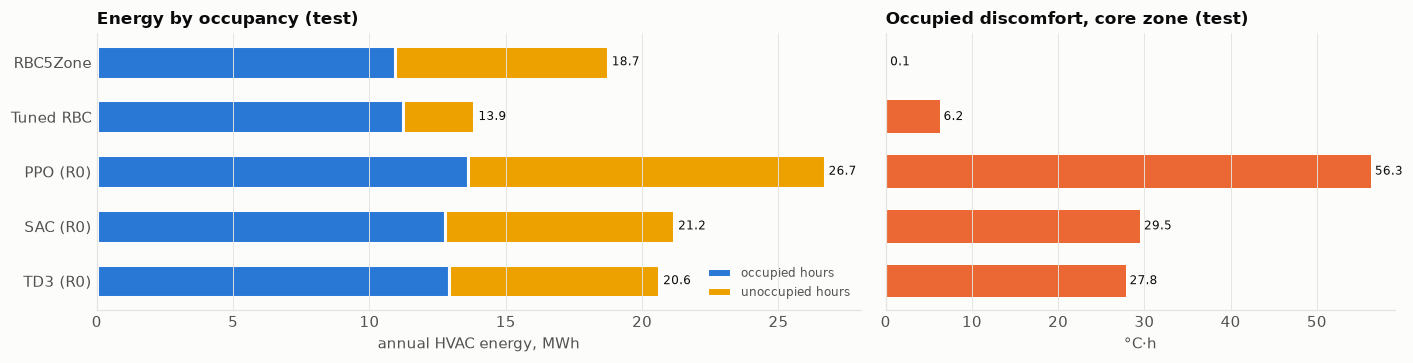

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={"width_ratios": [3, 2]})
y = np.arange(len(r0_test))
ax1.barh(y, r0_test["energy_occ_MWh"], color=SERIES[0], height=0.6, label="occupied hours",
         edgecolor=SURFACE, linewidth=2)
ax1.barh(y, r0_test["energy_unocc_MWh"], left=r0_test["energy_occ_MWh"], color=SERIES[3], height=0.6,
         label="unoccupied hours", edgecolor=SURFACE, linewidth=2)
for yi, v in zip(y, r0_test["energy_MWh"]):
    ax1.text(v, yi, f" {v:.1f}", va="center", fontsize=8, color=TEXT)
ax1.set_yticks(y, r0_test.index)
ax1.invert_yaxis()
ax1.grid(axis="y", visible=False)
ax1.set(xlabel="annual HVAC energy, MWh", title="Energy by occupancy (test)")
ax1.legend(loc="lower right", fontsize=8)

ax2.barh(y, r0_test["discomfort_occ_Ch"], color=SERIES[1], height=0.6)
for yi, v in zip(y, r0_test["discomfort_occ_Ch"]):
    ax2.text(v, yi, f" {v:.1f}", va="center", fontsize=8, color=TEXT)
ax2.set_yticks(y, [])
ax2.invert_yaxis()
ax2.grid(axis="y", visible=False)
ax2.set(xlabel="°C·h", title="Occupied discomfort, core zone (test)")
fig.tight_layout()

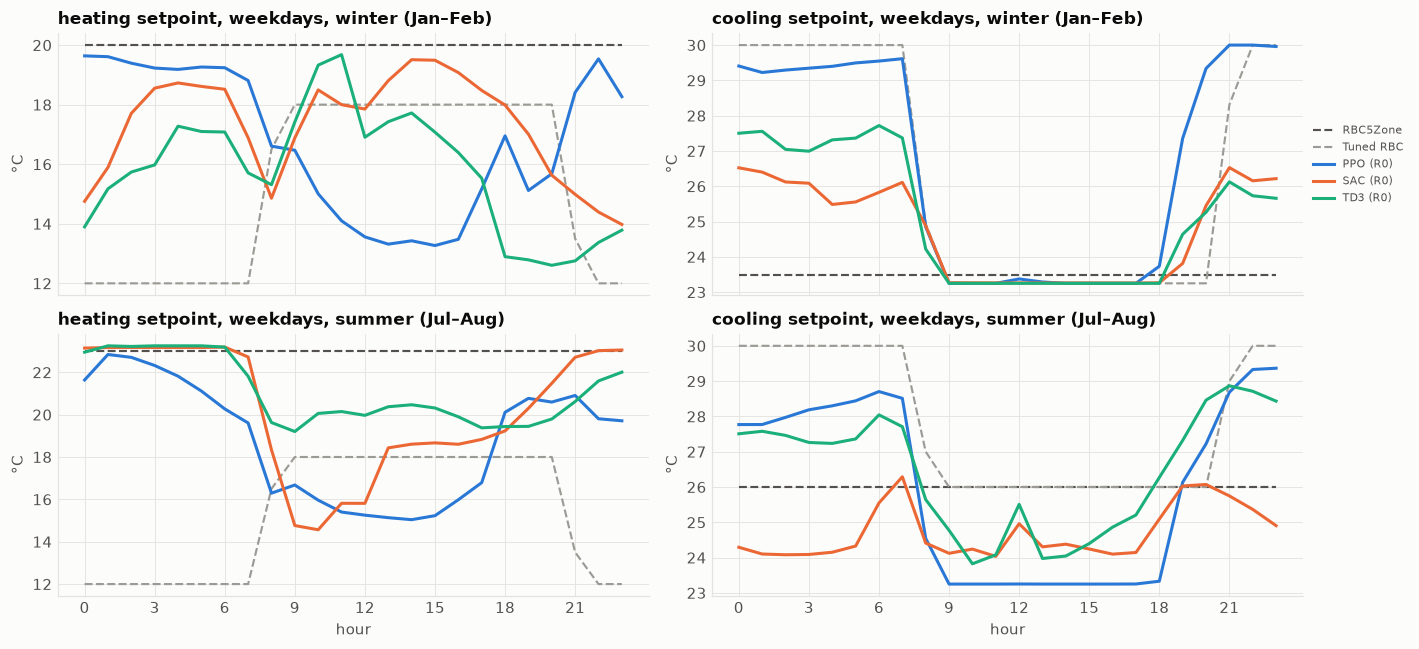

In [24]:
logs = {lab: base[("test", n)] for n, lab in BASE_RUNS.items()}
logs.update({lab: rr.load_eval_log(r, "test") for r, lab in R0_RUNS.items()})

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
for row, (months, season) in enumerate([([1, 2], "winter (Jan–Feb)"), ([7, 8], "summer (Jul–Aug)")]):
    for col, (sp, name) in enumerate([("a_heat", "heating"), ("a_cool", "cooling")]):
        ax = axes[row, col]
        for (lab, d), c in zip(logs.items(), [TEXT_2, "#9b9a94", *SERIES]):
            wd = d[d.month.isin(months) & (d.groupby(["month", "day_of_month"])["people_occupant"].transform("max") > 0)]
            prof = wd.groupby("hour")[sp].mean()
            ax.plot(prof, color=c, lw=2 if "R0" in lab else 1.4, ls="-" if "R0" in lab else "--", label=lab)
        ax.set(title=f"{name} setpoint, weekdays, {season}", ylabel="°C", xticks=range(0, 24, 3))
for ax in axes[1]:
    ax.set_xlabel("hour")
axes[0, 1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()

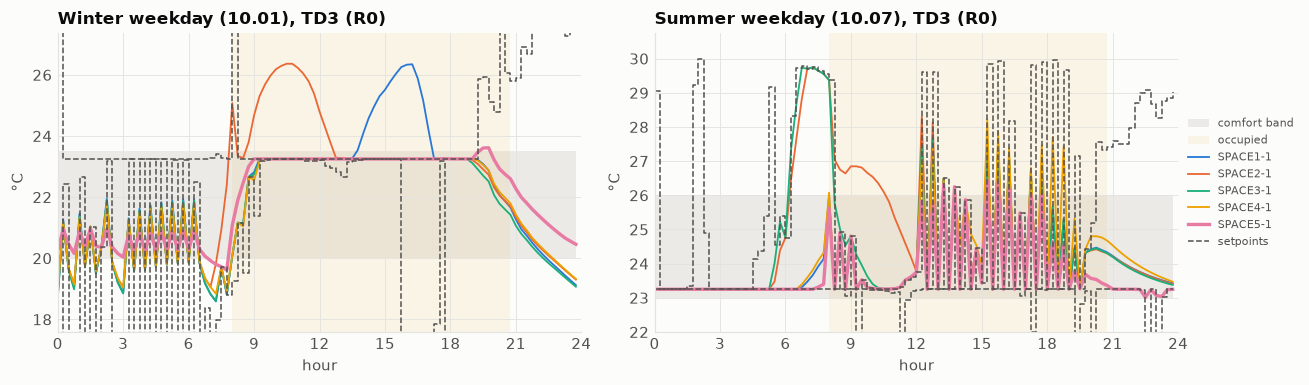

In [25]:
plot_days(rr.load_eval_log("td3_r0_s1", "test"), "TD3 (R0)")

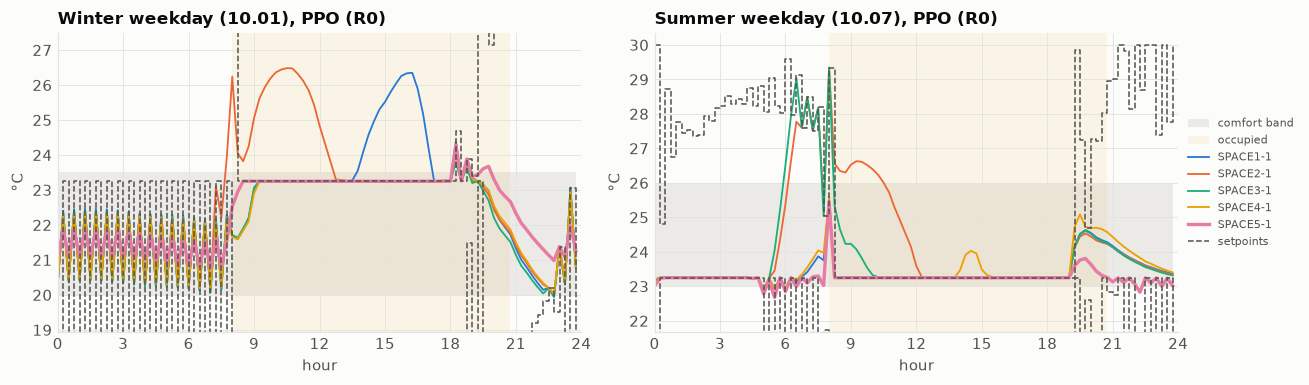

In [26]:
plot_days(rr.load_eval_log("ppo_r0_s1", "test"), "PPO (R0)")

Agents trained on R0 follow exactly what R0 rewards. They keep conditioning the empty building and **use 10–42 % more energy than RBC5Zone**, while also accumulating 28–56 °C·h of overheating. None of them learned the night setback.

### 3.5 Agents trained on R0: stress climates

In [27]:
pd.concat({split: compare(split) for split in ["stress_mixed", "stress_cool"]})

energy_MWh  energy_occ_MWh  energy_unocc_MWh  \
stress_mixed RBC5Zone        20.59            6.10             14.49   
             Tuned RBC        9.04            6.19              2.85   
             PPO (R0)        30.52            8.94             21.57   
             SAC (R0)        20.31            8.08             12.22   
             TD3 (R0)        21.45            8.36             13.09   
stress_cool  RBC5Zone        18.03            3.19             14.85   
             Tuned RBC        4.53            3.23              1.29   
             PPO (R0)        23.67            4.59             19.08   
             SAC (R0)        11.40            4.30              7.10   
             TD3 (R0)        13.62            4.30              9.32   

                        power_peak_kw  discomfort_occ_Ch  \
stress_mixed RBC5Zone           19.82               0.09   
             Tuned RBC          19.07              55.32   
             PPO (R0)           22.43             103.82   
             SAC (R0)           21.96              18.03   
             TD3 (R0)           22.38              49.21   
stress_cool  RBC5Zone           11.94               0.26   
             Tuned RBC           9.90              46.47   
             PPO (R0)           15.03              95.26   
             SAC (R0)           14.64              32.21   
             TD3 (R0)           14.45              85.22   

                        discomfort_occ_hot_Ch  discomfort_unocc_Ch  \
stress_mixed RBC5Zone                    0.09                 1.43   
             Tuned RBC                   0.70              5081.22   
             PPO (R0)                  103.13               267.58   
             SAC (R0)                   12.66              1900.60   
             TD3 (R0)                   44.64              1237.05   
stress_cool  RBC5Zone                    0.26                 0.63   
             Tuned RBC                   0.00              5655.38   
             PPO (R0)                   94.36               616.66   
             SAC (R0)                   11.07              4159.53   
             TD3 (R0)                   61.69              3254.13   

                        frac_occ_bound_violating        R0   R1_w0.5  rank R0  \
stress_mixed RBC5Zone                   0.00e+00  -4121.73 -19157.21        1   
             Tuned RBC                  9.43e-03 -12074.63  -8637.12        5   
             PPO (R0)                   5.16e-03  -6416.18 -27966.92        2   
             SAC (R0)                   0.00e+00  -7780.26 -18666.98        4   
             TD3 (R0)                   5.31e-03  -6787.20 -20202.04        3   
stress_cool  RBC5Zone                   0.00e+00  -3609.16 -16779.64        1   
             Tuned RBC                  1.33e-02 -12303.71  -4408.46        5   
             PPO (R0)                   3.24e-03  -5894.29 -22109.83        2   
             SAC (R0)                   3.68e-04 -10599.86 -10664.14        4   
             TD3 (R0)                   1.54e-02  -9371.96 -13304.92        3   

                        rank R1 (w=0.5)  
stress_mixed RBC5Zone                 3  
             Tuned RBC                1  
             PPO (R0)                 5  
             SAC (R0)                 2  
             TD3 (R0)                 4  
stress_cool  RBC5Zone                 4  
             Tuned RBC                1  
             PPO (R0)                 5  
             SAC (R0)                 2  
             TD3 (R0)                 3

In the milder climates the R0 agents remain inefficient: they use 2–5 times the energy of the tuned RBC, and PPO uses even more than RBC5Zone.

### 3.6 R2: calibrated reward (v2)

The R1 runs (w = 0.5) revealed two problems:
- At w = 0.5, 1 °C·h of occupied discomfort costs only 4.3 kWh. The energy term made up 93–100 % of R1, and the agents traded comfort for energy: 56–105 °C·h on test against 0.05 for RBC5Zone.
- The observation contained neither the comfort band nor a calendar, so the agents confused the winter and summer bands.

**R2** sets the price of discomfort explicitly, in kWh per °C·h:

$$r_t = -\left[\frac{P_t}{P_{ref}} + \frac{\kappa}{\kappa_0}\,\mathbb{1}_{occ}\,\frac{\Delta T_t}{\Delta T_{ref}} + \lambda\,\|\Delta a_t\|_{norm}\right], \qquad \kappa_0 = \frac{P_{ref}}{\Delta T_{ref}} = 4.3\ \mathrm{kWh}/(^\circ\mathrm{C}\cdot\mathrm{h})$$

- κ = 50 (sweep: 25 and 100), λ = 0.2. R2 equals R1 with w = κ₀/(κ₀+κ) ≈ 0.08, i.e. a much higher price of comfort.
- Maximising R2 is equivalent, up to the smoothness term, to minimising the KPI J_κ = kWh + κ·°C·h, so the reward and the metric agree by construction (5.6: ρ = 1.0).

**Other v2 changes** (ablations in 5.4):
- Observation: comfort band and margins + calendar (`hour_sin/cos`, `workday`, `hours_to_occ`).
- Residual action: tuned RBC setpoints + u·Δ (Δ = 2 °C occupied, 7 °C unoccupied); u = 0 reproduces the tuned RBC exactly.

## 4. Training

All runs are launched from the terminal with scripts; the notebook only loads their results. Each agent is trained for 10 simulated years and evaluated on the validation year after every year of training.

### 4.1 Training runs (from logs)

In [28]:
from hvac_rl import runs as rr

rr.progress()

,algo,reward,seed,status,steps,progress_%,steps_per_s,elapsed_min,eta_min,log_idle_min
run,,,,,,,,,,
ppo_r0_s1,PPO,R0,1,done,350400,100.0,NaN,11.15,0.0,1657.86
ppo_r1_w0.5_s1,PPO,R1 w=0.5,1,done,350400,100.0,554.9,11.02,0.0,1535.36
sac_r0_s1,SAC,R0,1,done,350400,100.0,84.7,69.57,0.0,1579.08
sac_r1_w0.5_s1,SAC,R1 w=0.5,1,done,350400,100.0,84.2,69.85,0.0,1476.53
td3_r0_s1,TD3,R0,1,done,350400,100.0,70.3,83.65,0.0,1565.00
td3_r1_w0.5_s1,TD3,R1 w=0.5,1,done,350400,100.0,71.9,81.65,0.0,1464.72


Each run covers 10 simulated years (350 400 steps). PPO is about 7 times faster than SAC and TD3 (11 min against 70–85 min per run).

### 4.2 Training monitor (validation, one point per simulated year)

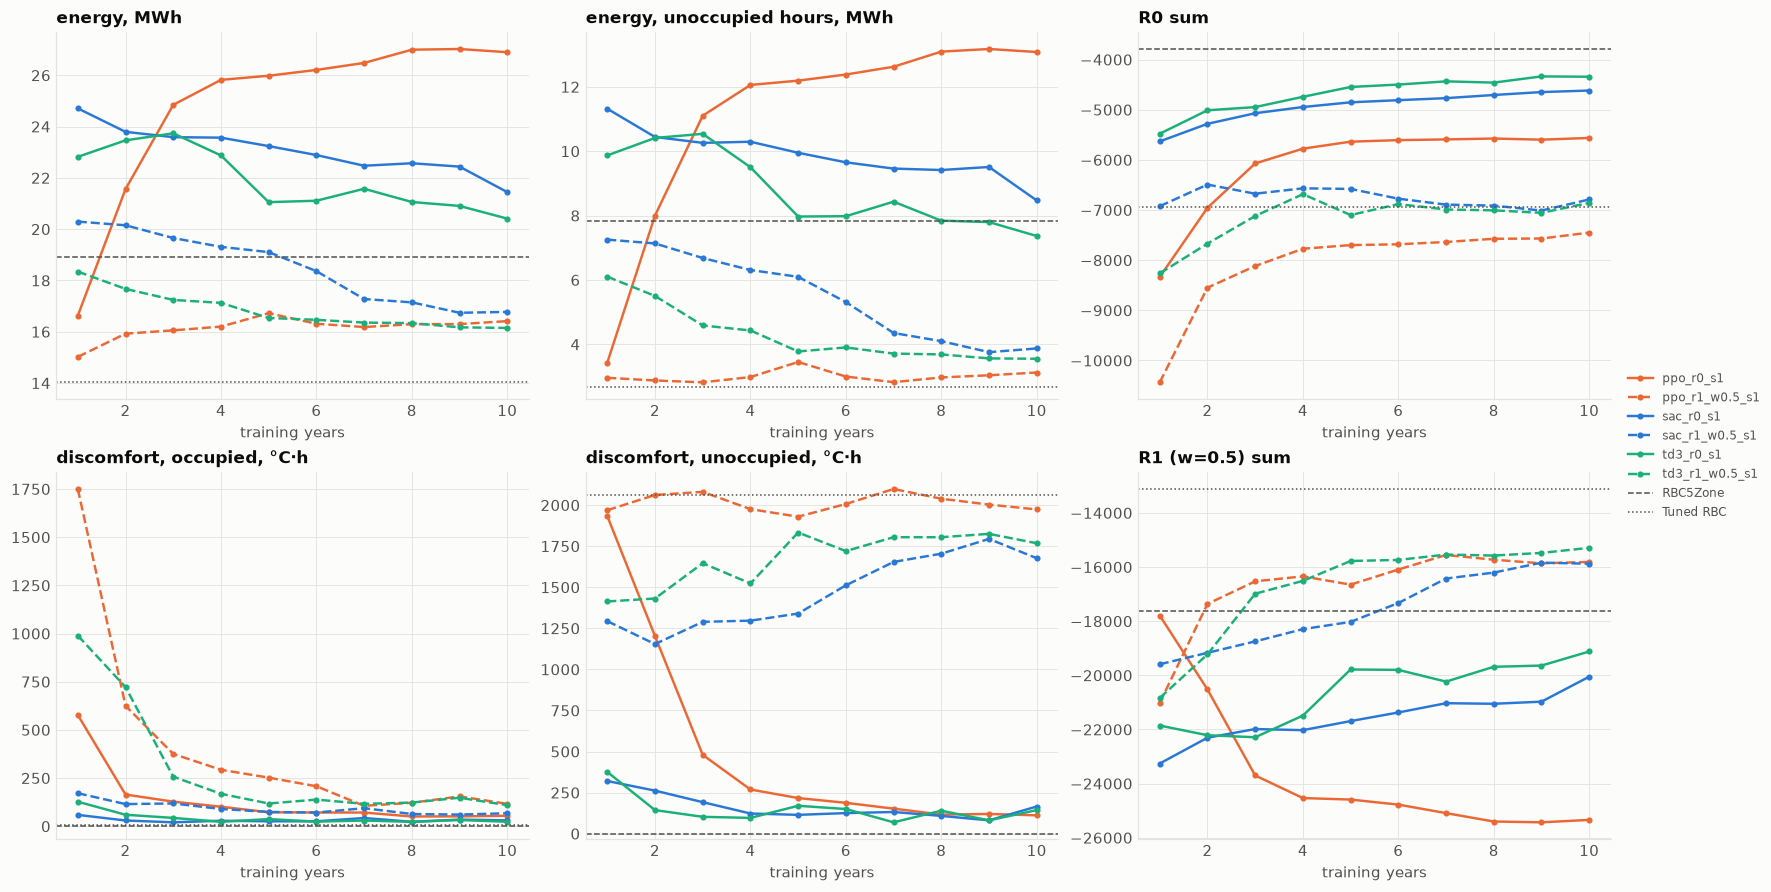

In [29]:
from hvac_rl import runs as rr
from hvac_rl.evaluate import policy_metrics

YEAR = 35040
val = rr.load_val()
ref = {LABELS[n]: policy_metrics(base[("val", n)]) for n in ["rbc5zone", "tuned_rbc_w0.5"]}
panels = [("energy_kwh", "energy, MWh", 1e-3), ("energy_unocc_kwh", "energy, unoccupied hours, MWh", 1e-3),
          ("R0", "R0 sum", 1), ("discomfort_occ_Ch", "discomfort, occupied, °C·h", 1),
          ("discomfort_unocc_Ch", "discomfort, unoccupied, °C·h", 1), ("R1_w0.5", "R1 (w=0.5) sum", 1)]

if val.empty:
    print("No training runs yet")
else:
    algo_color = {"SAC": SERIES[0], "PPO": SERIES[1], "TD3": SERIES[2]}
    reward_style = {"R0": "-", "R1 w=0.5": "--"}
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), layout="constrained")
    for ax, (col, title, k) in zip(axes.flat, panels):
        for run, d in val.groupby("run"):
            ax.plot(d["timesteps"] / YEAR, d[col] * k, marker="o", ms=3, label=run,
                    color=algo_color.get(d["algo"].iloc[0], SERIES[3]), ls=reward_style.get(d["reward"].iloc[0], ":"))
        for (name, m), ls in zip(ref.items(), ["--", ":"]):
            ax.axhline(m[col] * k, color=TEXT_2, lw=1, ls=ls, label=name)
        ax.set(title=title, xlabel="training years")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside right center", fontsize=8, frameon=False)

    last = val.sort_values("timesteps").groupby("run").tail(1).set_index("run")
    cols = ["algo", "reward", "seed", "years", "energy_MWh", "energy_unocc_kwh", "discomfort_occ_Ch",
            "discomfort_unocc_Ch", "R0", "R1_w0.5", "frac_occ_bound_violating", "wall_s"]
    last.assign(years=last["timesteps"] / YEAR, energy_MWh=last["energy_kwh"] / 1e3).reindex(columns=cols)

Each point is an evaluation on the validation year after one more year of training. R0 agents stay at 20–27 MWh. R1 agents quickly reach 16–17 MWh, but their discomfort stays at 67–116 °C·h: **R1 does not penalise discomfort strongly enough**, which motivated R2.

### 4.3 Training monitor: R2 (v2)

,algo,reward,variant,seed,status,steps,progress_%,steps_per_s,elapsed_min,eta_min,log_idle_min
run,,,,,,,,,,,
ppo_r2_k50_s1,PPO,R2 κ=50,band_time,1,done,350400,100.0,305.4,20.01,0.0,1032.05
ppo_r2_k50_s2,PPO,R2 κ=50,band_time,2,done,350400,100.0,305.3,20.00,0.0,1032.05
ppo_r2_k50_s3,PPO,R2 κ=50,band_time,3,done,350400,100.0,288.2,21.22,0.0,918.01
sac_r2_k100_s1,SAC,R2 κ=100,band_time,1,done,350400,100.0,65.9,89.22,0.0,849.90
sac_r2_k25_s1,SAC,R2 κ=25,band_time,1,done,350400,100.0,65.2,90.10,0.0,849.07
sac_r2_k50_base_s1,SAC,R2 κ=50,base,1,done,350400,100.0,70.2,83.68,0.0,838.77
sac_r2_k50_s1,SAC,R2 κ=50,band_time,1,done,350400,100.0,52.1,112.81,0.0,939.25
sac_r2_k50_s2,SAC,R2 κ=50,band_time,2,done,350400,100.0,52.2,112.68,0.0,939.38
sac_r2_k50_s3,SAC,R2 κ=50,band_time,3,done,350400,100.0,50.8,115.62,0.0,916.34


,algo,variant,seed,years,energy_MWh,energy_unocc_kwh,discomfort_occ_Ch,discomfort_unocc_Ch,J_k50,R2_k50,frac_occ_bound_violating
run,,,,,,,,,,,
sac_res_k50_s3,SAC,residual,3,10.0,15.33,2785.73,5.87,2097.15,15623.55,-29303.30,1.55e-03
sac_res_k50_s2,SAC,residual,2,10.0,14.90,2821.96,5.58,2133.98,15179.77,-28466.70,1.55e-03
sac_res_k50_s1,SAC,residual,1,10.0,14.91,2740.06,4.69,2099.27,15147.48,-28403.12,1.69e-03
sac_r2_k50_s3,SAC,band_time,3,10.0,16.66,3371.30,2.70,1867.36,16791.94,-31549.05,0.00e+00
sac_r2_k50_s2,SAC,band_time,2,10.0,16.83,3458.47,3.02,1931.60,16976.21,-31857.16,0.00e+00
sac_r2_k50_s1,SAC,band_time,1,10.0,16.93,3530.99,3.34,1985.27,17096.21,-32054.42,7.37e-05
sac_r2_k25_s1,SAC,band_time,1,10.0,16.53,3370.94,5.16,1855.50,16785.96,-31446.38,0.00e+00
sac_r2_k50_base_s1,SAC,base,1,10.0,17.88,4397.90,6.53,1837.75,18208.74,-34086.62,1.47e-04
ppo_r2_k50_s3,PPO,band_time,3,10.0,16.52,2849.05,4.65,2165.16,16754.83,-31298.90,2.06e-03


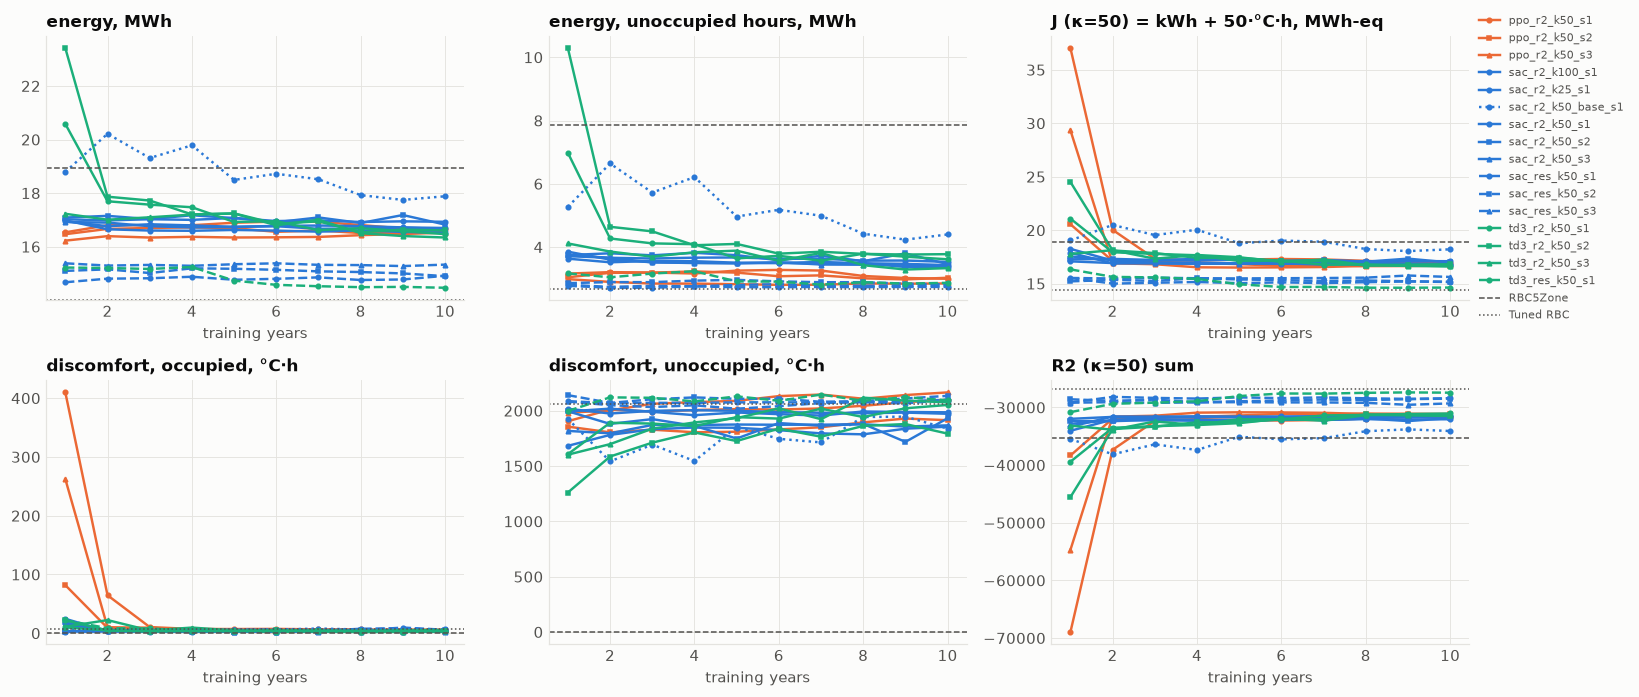

In [30]:
from hvac_rl import runs_v2 as rv
from hvac_rl.evaluate_v2 import metrics_v2

display(rv.progress())

val2 = rv.load_val()
ref2 = {LABELS[n]: metrics_v2(base[("val", n)]) for n in ["rbc5zone", "tuned_rbc_w0.5"]}
panels2 = [("energy_kwh", "energy, MWh", 1e-3), ("energy_unocc_kwh", "energy, unoccupied hours, MWh", 1e-3),
           ("J_k50", "J (κ=50) = kWh + 50·°C·h, MWh-eq", 1e-3), ("discomfort_occ_Ch", "discomfort, occupied, °C·h", 1),
           ("discomfort_unocc_Ch", "discomfort, unoccupied, °C·h", 1), ("R2_k50", "R2 (κ=50) sum", 1)]

if val2.empty:
    print("No R2 validation results yet")
else:
    algo_color = {"SAC": SERIES[0], "PPO": SERIES[1], "TD3": SERIES[2]}
    variant_style = {"band_time": "-", "residual": "--", "base": ":"}
    seed_marker = {1: "o", 2: "s", 3: "^"}
    fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
    for ax, (col, title, k) in zip(axes.flat, panels2):
        for run, d in val2.groupby("run"):
            r = d.iloc[0]
            ax.plot(d["timesteps"] / YEAR, d[col] * k, color=algo_color.get(r["algo"], SERIES[3]),
                    ls=variant_style.get(r["variant"], "-."), marker=seed_marker.get(r["seed"], "o"), ms=3,
                    label=run)
        for (name, m), ls in zip(ref2.items(), ["--", ":"]):
            ax.axhline(m[col] * k, color=TEXT_2, lw=1, ls=ls, label=name)
        ax.set(title=title, xlabel="training years")
    axes[0, 2].legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.tight_layout()

    last2 = val2.sort_values("timesteps").groupby("run").tail(1).set_index("run")
    cols2 = ["algo", "variant", "seed", "years", "energy_MWh", "energy_unocc_kwh", "discomfort_occ_Ch",
             "discomfort_unocc_Ch", "J_k50", "R2_k50", "frac_occ_bound_violating"]
    display(last2.assign(years=last2["timesteps"] / YEAR, energy_MWh=last2["energy_kwh"] / 1e3).reindex(columns=cols2))

With R2 every agent converges to **J ≈ 16.6–17.1 MWh-eq on validation**, and the residual agents to 14.6–15.6, close to 14.4 for the tuned RBC. The curves flatten after a few years, so the 10-year budget is sufficient.

## 5. Agent comparison on test

All controllers are compared by one score, **J (κ = 50) = kWh + 50 · °C·h**: one °C·h of occupied discomfort counts as 50 kWh, and lower is better.
Checkpoints were selected on validation, never on test. "±" is the standard deviation over 3 seeds.

### 5.1 Test KPIs (mean ± std over seeds)

In [31]:
cmp = {s: rv.comparison(s, base) for s in ["test", "stress_mixed", "stress_cool"]}
summ = {s: rv.summarize(c) for s, c in cmp.items()}
TABLE = {"energy_kwh": ("energy, MWh", 1e-3), "energy_unocc_kwh": ("energy unocc, MWh", 1e-3),
         "power_peak_kw": ("peak, kW", 1), "discomfort_occ_Ch": ("discomfort occ, °C·h", 1),
         "discomfort_unocc_Ch": ("discomfort unocc, °C·h", 1), "J_k50": ("J (κ=50), MWh-eq", 1e-3)}
BASE_KEY, REF_KEY = rv.BASELINE_KEY, rv.REFERENCE_KEY
FAMILY_COLOR = {"baseline": TEXT, "reference": TEXT_2, "v1 R0": "#9b9a94", "v1 R1": "#c3c2bc", "v2 R2": SERIES[0], "v2 residual": SERIES[1]}


def pm_table(s):
    t = pd.DataFrame({lab: [f"{m * k:,.2f}" + (f" ± {sd * k:,.2f}" if n > 1 else "")
                            for m, sd, n in zip(s[c], s[f"{c}_std"], s["n_seeds"])]
                      for c, (lab, k) in TABLE.items()}, index=s.index)
    rel = lambda key: (100 * (s["J_k50"] / s.loc[key, "J_k50"] - 1)).round(1)
    return t.assign(**{"J vs RBC5Zone, %": rel(BASE_KEY), "J vs Tuned RBC, %": rel(REF_KEY), "seeds": s["n_seeds"]})


pm_table(summ["test"])

energy, MWh energy unocc, MWh  \
family      controller                                                
baseline    Fixed 21/24                     21.24              9.38   
            RBC5Zone (baseline)             18.74              7.80   
reference   Tuned RBC (reference)           13.85              2.63   
v1 R0       PPO (R0)                        26.69             13.08   
            SAC (R0)                        21.17              8.39   
            TD3 (R0)                        20.63              7.72   
v1 R1       PPO (R1 w=0.5)                  15.95              2.80   
            SAC (R1 w=0.5)                  16.53              3.73   
            TD3 (R1 w=0.5)                  15.93              3.50   
v2 R2       PPO (R2 κ=50)            16.25 ± 0.17       2.91 ± 0.11   
            SAC (R2 κ=100)                  16.47              3.39   
            SAC (R2 κ=25)                   16.29              3.33   
            SAC (R2 κ=50)            16.57 ± 0.14       3.45 ± 0.07   
            SAC (R2 κ=50, base obs)         17.48              4.18   
            TD3 (R2 κ=50)            16.21 ± 0.12       3.54 ± 0.25   
v2 residual SAC residual (R2 κ=50)   14.78 ± 0.25       2.72 ± 0.05   
            TD3 residual (R2 κ=50)          14.30              2.79   

                                         peak, kW discomfort occ, °C·h  \
family      controller                                                   
baseline    Fixed 21/24                      9.68               999.56   
            RBC5Zone (baseline)              8.38                 0.05   
reference   Tuned RBC (reference)            8.65                 6.25   
v1 R0       PPO (R0)                        11.25                56.27   
            SAC (R0)                        12.61                29.49   
            TD3 (R0)                        12.35                27.82   
v1 R1       PPO (R1 w=0.5)                  10.52               104.66   
            SAC (R1 w=0.5)                  11.98                56.27   
            TD3 (R1 w=0.5)                  12.13               103.88   
v2 R2       PPO (R2 κ=50)             9.96 ± 0.34          3.92 ± 1.48   
            SAC (R2 κ=100)                  11.33                 3.20   
            SAC (R2 κ=25)                   10.50                 4.52   
            SAC (R2 κ=50)            10.09 ± 0.29          3.13 ± 0.37   
            SAC (R2 κ=50, base obs)         10.12                 5.73   
            TD3 (R2 κ=50)            13.48 ± 0.51          3.88 ± 1.93   
v2 residual SAC residual (R2 κ=50)    9.68 ± 0.56          4.15 ± 1.30   
            TD3 residual (R2 κ=50)          11.84                 2.32   

                                    discomfort unocc, °C·h J (κ=50), MWh-eq  \
family      controller                                                        
baseline    Fixed 21/24                           1,306.29            71.21   
            RBC5Zone (baseline)                       0.22            18.74   
reference   Tuned RBC (reference)                 2,048.99            14.16   
v1 R0       PPO (R0)                                114.88            29.51   
            SAC (R0)                                149.18            22.65   
            TD3 (R0)                                 79.73            22.02   
v1 R1       PPO (R1 w=0.5)                        2,088.20            21.18   
            SAC (R1 w=0.5)                        1,773.21            19.34   
            TD3 (R1 w=0.5)                        1,750.96            21.12   
v2 R2       PPO (R2 κ=50)                2,021.64 ± 102.83     16.45 ± 0.23   
            SAC (R2 κ=100)                        1,978.96            16.63   
            SAC (R2 κ=25)                         1,863.45            16.51   
            SAC (R2 κ=50)                 1,937.33 ± 59.67     16.72 ± 0.15   
            SAC (R2 κ=50, base obs)               1,942.53            17.77   
            TD3 (

**This is the main result.** With R2, all three algorithms beat the RBC5Zone baseline by **11–14 % in J** (16.2–16.6 MWh of energy instead of 18.7) with only 3–4 °C·h of discomfort, and the **residual agents reach −20…−23 %**. With R0 or R1 the same algorithms were worse than the baseline. The tuned RBC remains slightly better than every agent.

### 5.2 Cost, energy and discomfort (test)

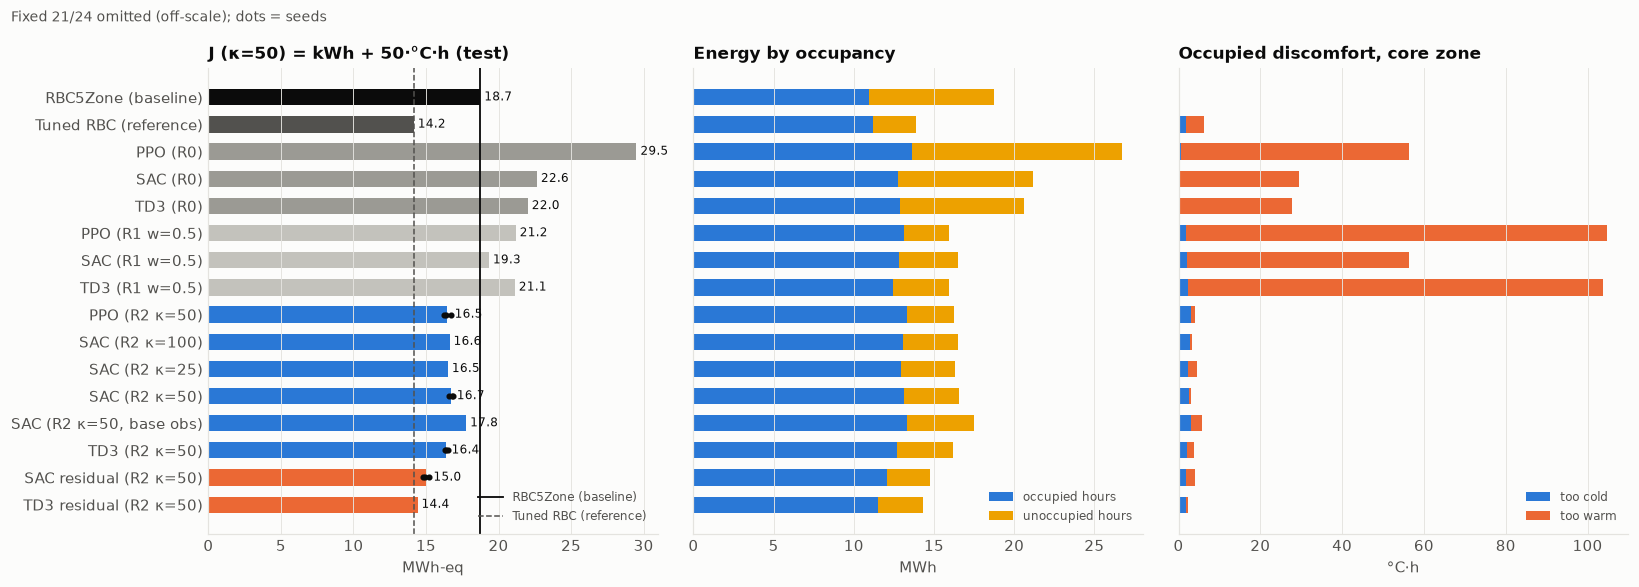

In [32]:
def bar_panels(split):
    s = summ[split].drop(index=("baseline", "Fixed 21/24"))
    c = cmp[split]
    y = np.arange(len(s))
    names = s.index.get_level_values("controller")
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5.4), sharey=True)
    ax1.barh(y, s["J_k50"] / 1e3, color=[FAMILY_COLOR[f] for f in s.index.get_level_values("family")], height=0.6)
    for yi, name in zip(y, names):
        pts = c.loc[c["controller"] == name, "J_k50"] / 1e3
        if len(pts) > 1:
            ax1.scatter(pts, np.full(len(pts), yi), color=TEXT, s=9, zorder=3)
        ax1.text(pts.max(), yi, f" {pts.mean():.1f}", va="center", fontsize=8, color=TEXT)
    ax1.axvline(s.loc[BASE_KEY, "J_k50"] / 1e3, color=TEXT, lw=1.2, label="RBC5Zone (baseline)")
    ax1.axvline(s.loc[REF_KEY, "J_k50"] / 1e3, color=TEXT_2, lw=1, ls="--", label="Tuned RBC (reference)")
    ax1.legend(fontsize=8, loc="lower right")
    ax1.set(xlabel="MWh-eq", title=f"J (κ=50) = kWh + 50·°C·h ({split})")
    ax2.barh(y, s["energy_occ_kwh"] / 1e3, color=SERIES[0], height=0.6, label="occupied hours")
    ax2.barh(y, s["energy_unocc_kwh"] / 1e3, left=s["energy_occ_kwh"] / 1e3, color=SERIES[3], height=0.6,
             label="unoccupied hours")
    ax2.set(xlabel="MWh", title="Energy by occupancy")
    ax2.legend(fontsize=8, loc="lower right")
    ax3.barh(y, s["discomfort_occ_cold_Ch"], color=SERIES[0], height=0.6, label="too cold")
    ax3.barh(y, s["discomfort_occ_hot_Ch"], left=s["discomfort_occ_cold_Ch"], color=SERIES[1], height=0.6,
             label="too warm")
    ax3.set(xlabel="°C·h", title="Occupied discomfort, core zone")
    ax3.legend(fontsize=8, loc="lower right")
    ax1.set_yticks(y, names)
    ax1.invert_yaxis()
    for ax in (ax1, ax2, ax3):
        ax.grid(axis="y", visible=False)
    fig.suptitle("Fixed 21/24 omitted (off-scale); dots = seeds", x=0.01, ha="left", fontsize=9, color=TEXT_2)
    fig.tight_layout()


bar_panels("test")

The saving comes from the **unoccupied hours** (orange bars): R2 agents spend 2.7–3.5 MWh there, RBC5Zone 7.8 MWh. The large overheating of the R0 and R1 agents disappears with R2.

### 5.3 Energy–discomfort trade-off (test)

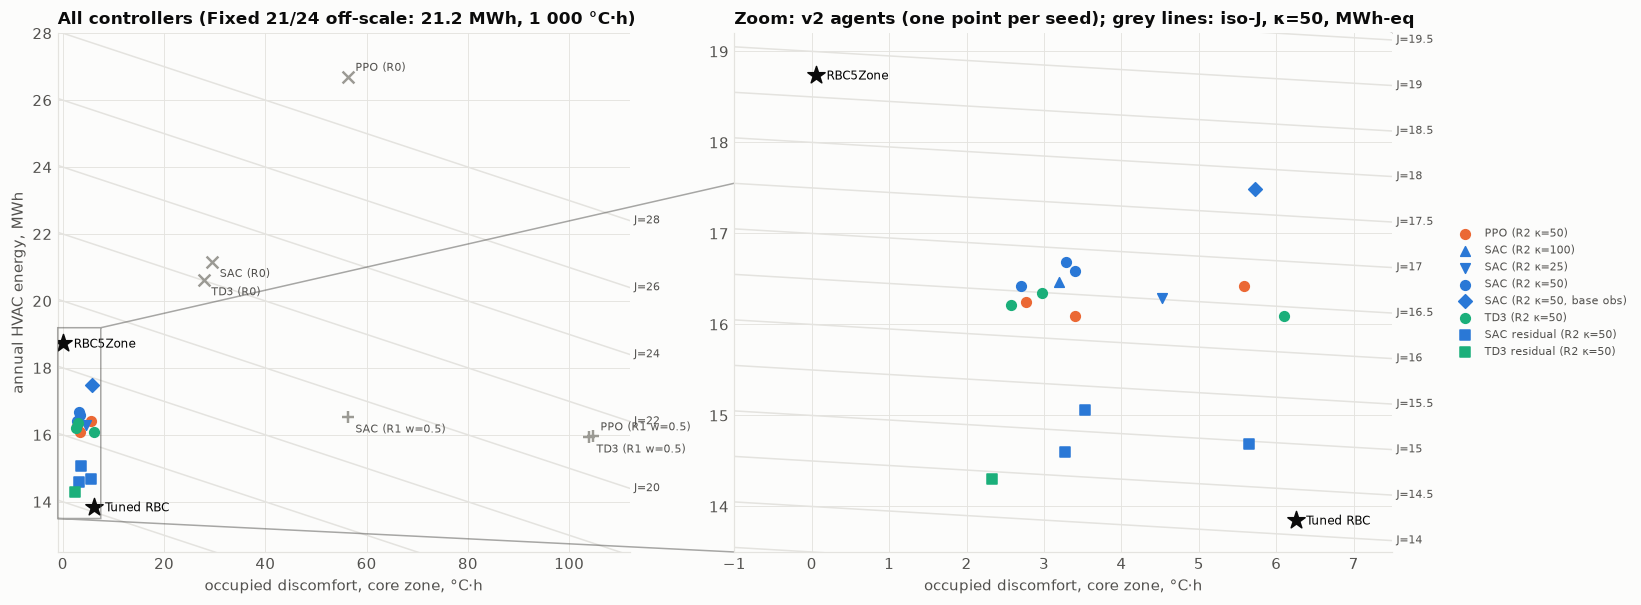

In [33]:
c = cmp["test"]
algo_color = {"SAC": SERIES[0], "PPO": SERIES[1], "TD3": SERIES[2]}
MARKER = {("band_time", 50.0): "o", ("band_time", 25.0): "v", ("band_time", 100.0): "^", ("base", 50.0): "D",
          ("residual", 50.0): "s"}
v2 = c[c["family"].str.startswith("v2")]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1, 1.15]})
for ax, (xmax, ymin, ymax) in zip((ax1, ax2), [(112, 12.5, 28), (7.5, 13.5, 19.2)]):
    D = np.linspace(-1, xmax, 50)
    for j in np.arange(10, 30, 2 if ax is ax1 else 0.5):
        ax.plot(D, j - 0.05 * D, color=GRID, lw=1, zorder=0)
        y_end = j - 0.05 * xmax
        if ymin < y_end < ymax:
            ax.text(xmax, y_end, f" J={j:g}", fontsize=7, color=TEXT_2, va="center")
    for _, r in c[c["family"].isin(["baseline", "reference"])].iterrows():
        if r["controller"] != "Fixed 21/24":
            ax.scatter(r["discomfort_occ_Ch"], r["energy_kwh"] / 1e3, color=TEXT, marker="*", s=140, zorder=4)
            ax.annotate(r["controller"].split(" (")[0], (r["discomfort_occ_Ch"], r["energy_kwh"] / 1e3), xytext=(7, -3),
                        textcoords="offset points", fontsize=8)
    for name, g in v2.groupby("controller", sort=False):
        ax.scatter(g["discomfort_occ_Ch"], g["energy_kwh"] / 1e3, color=algo_color[g["algo"].iloc[0]],
                   marker=MARKER[(g["variant"].iloc[0], g["kappa"].iloc[0])], s=40, zorder=4,
                   label=name if ax is ax2 else None)
    ax.set(xlim=(-1, xmax), ylim=(ymin, ymax), xlabel="occupied discomfort, core zone, °C·h")
for _, r in c[c["family"].str.startswith("v1")].iterrows():
    ax1.scatter(r["discomfort_occ_Ch"], r["energy_kwh"] / 1e3, color="#9b9a94",
                marker="x" if "R0" in r["family"] else "+", s=60, zorder=3)
    ax1.annotate(r["controller"], (r["discomfort_occ_Ch"], r["energy_kwh"] / 1e3), xytext=(5, 4 if "PPO" in r["controller"] else -10),
                 textcoords="offset points", fontsize=7, color=TEXT_2)
ax1.indicate_inset_zoom(ax2, edgecolor=TEXT_2)
ax1.set(ylabel="annual HVAC energy, MWh", title="All controllers (Fixed 21/24 off-scale: 21.2 MWh, 1 000 °C·h)")
ax2.set(title="Zoom: v2 agents (one point per seed); grey lines: iso-J, κ=50, MWh-eq")
ax2.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.08, 0.5))
fig.tight_layout()

The grey lines are lines of equal J. All R2 agents lie between RBC5Zone and the tuned RBC: much less energy than the baseline at slightly more discomfort. Agents trained with different κ (triangles) fall into the same cluster.

### 5.4 Ablation: observation and action parameterisation (seed 1, test)

In [34]:
ABLATION = {"sac_r2_k50_base_s1": "SAC, base obs", "sac_r2_k50_s1": "SAC, band/time obs",
            "sac_res_k50_s1": "SAC residual, band/time obs", "td3_r2_k50_s1": "TD3, band/time obs",
            "td3_res_k50_s1": "TD3 residual, band/time obs"}
a = cmp["test"].set_index("run").loc[list(ABLATION)].rename(index=ABLATION)
pd.DataFrame({
    "energy_MWh": a["energy_kwh"] / 1e3, "energy_unocc_MWh": a["energy_unocc_kwh"] / 1e3,
    "peak_kW": a["power_peak_kw"], "discomfort_occ_Ch": a["discomfort_occ_Ch"], "J_k50_MWh": a["J_k50"] / 1e3,
    "J vs RBC5Zone, %": 100 * (a["J_k50"] / summ["test"].loc[BASE_KEY, "J_k50"] - 1),
    "J vs Tuned RBC, %": 100 * (a["J_k50"] / summ["test"].loc[REF_KEY, "J_k50"] - 1),
    "frac_heat_at_min": a["frac_heat_at_min"], "frac_cool_at_max": a["frac_cool_at_max"],
    "best val checkpoint, years": a["checkpoint"].astype(int) / YEAR,
})

,energy_MWh,energy_unocc_MWh,peak_kW,discomfort_occ_Ch,J_k50_MWh,"J vs RBC5Zone, %","J vs Tuned RBC, %",frac_heat_at_min,frac_cool_at_max,"best val checkpoint, years"
run,,,,,,,,,,
"SAC, base obs",17.48,4.18,10.12,5.73,17.77,-5.19,25.47,4.17e-03,1.17e-03,9.0
"SAC, band/time obs",16.69,3.53,10.06,3.28,16.85,-10.10,18.97,1.31e-03,4.85e-04,8.0
"SAC residual, band/time obs",14.60,2.68,9.05,3.28,14.76,-21.25,4.22,4.29e-01,3.56e-01,2.0
"TD3, band/time obs",16.21,3.56,14.06,2.57,16.34,-12.82,15.37,3.58e-01,9.85e-02,10.0
"TD3 residual, band/time obs",14.30,2.79,11.84,2.32,14.42,-23.08,1.80,3.53e-01,4.33e-01,9.0


The runs in the table (seed 1) differ in one factor at a time. **The structure of the agent matters more than the weight.** Adding the comfort band and the calendar to the observation lowers J by 5 %, and the residual action on top of the tuned RBC lowers it by a further 12 %.

### 5.5 Sensitivity to κ (SAC, band/time obs, seed 1, test)

In [35]:
k = cmp["test"]
k = k[(k["algo"] == "SAC") & (k["variant"] == "band_time") & (k["seed"] == 1)].set_index("kappa").sort_index()
tuned_t = cmp["test"].set_index("run").loc["tuned_rbc_w0.5"]
pd.DataFrame({
    "energy_MWh": k["energy_kwh"] / 1e3, "discomfort_occ_Ch": k["discomfort_occ_Ch"],
    **{f"J_k{x} vs Tuned RBC, %": 100 * (k[f"J_k{x}"] / tuned_t[f"J_k{x}"] - 1) for x in [25, 50, 100]},
}).rename_axis("trained with κ")

,energy_MWh,discomfort_occ_Ch,"J_k25 vs Tuned RBC, %","J_k50 vs Tuned RBC, %","J_k100 vs Tuned RBC, %"
trained with κ,,,,,
25.0,16.29,4.52,17.08,16.58,15.63
50.0,16.69,3.28,19.72,18.97,17.54
100.0,16.47,3.20,18.13,17.39,15.96


Changing κ from 25 to 100 moves energy by less than 0.4 MWh and discomfort by about 1 °C·h, which is smaller than the difference between seeds. Once comfort is met almost all the time, the weight has little left to trade.

### 5.6 Reward vs KPI ranking (test)

In [36]:
s = summ["test"].droplevel("family")
ranks = pd.DataFrame({
    "J_k50 (KPI)": s["J_k50"].rank().astype(int),
    "R0": s["R0"].rank(ascending=False).astype(int),
    "R1 (w=0.5)": s["R1_w0.5"].rank(ascending=False).astype(int),
    "R2 (κ=50)": s["R2_k50"].rank(ascending=False).astype(int),
}).sort_values("J_k50 (KPI)")
rho = ranks.corr(method="spearman")["J_k50 (KPI)"].rename("Spearman ρ vs J_k50")
display(ranks)
rho.to_frame().T

,J_k50 (KPI),R0,R1 (w=0.5),R2 (κ=50)
controller,,,,
Tuned RBC (reference),1,6,1,1
TD3 residual (R2 κ=50),2,9,2,2
SAC residual (R2 κ=50),3,10,3,3
TD3 (R2 κ=50),4,11,5,4
PPO (R2 κ=50),5,14,6,5
SAC (R2 κ=25),6,8,7,6
SAC (R2 κ=100),7,13,9,7
SAC (R2 κ=50),8,12,10,8
"SAC (R2 κ=50, base obs)",9,15,12,9


,J_k50 (KPI),R0,R1 (w=0.5),R2 (κ=50)
Spearman ρ vs J_k50,1.0,-0.14,0.85,1.0


**This is the key check of the reward design.** The same 17 controllers are ranked by each reward and by the real KPI J: **R0 gives ρ = −0.14 (no relation), R1 gives ρ = 0.85, and R2 gives ρ = 1.00 (identical ranking)**. Maximising R2 therefore means optimising exactly the target KPI.

## 6. Stress tests

The agents are evaluated in the mixed and cool climates without retraining, to check whether the learned behaviour transfers to other weather.

### 6.1 Stress-climate KPIs (mean ± std over seeds)

In [37]:
pd.concat({s: pm_table(summ[s]) for s in ["stress_mixed", "stress_cool"]})

energy, MWh  \
             family      controller                              
stress_mixed baseline    Fixed 21/24                     23.56   
                         RBC5Zone (baseline)             20.59   
             reference   Tuned RBC (reference)            9.04   
             v1 R0       PPO (R0)                        30.52   
                         SAC (R0)                        20.31   
                         TD3 (R0)                        21.45   
             v1 R1       PPO (R1 w=0.5)                  10.85   
                         SAC (R1 w=0.5)                  13.68   
                         TD3 (R1 w=0.5)                  11.22   
             v2 R2       PPO (R2 κ=50)            11.94 ± 1.32   
                         SAC (R2 κ=100)                  10.96   
                         SAC (R2 κ=25)                   11.52   
                         SAC (R2 κ=50)            11.76 ± 0.31   
                         SAC (R2 κ=50, base obs)         12.33   
                         TD3 (R2 κ=50)            11.36 ± 0.22   
             v2 residual SAC residual (R2 κ=50)   10.51 ± 0.50   
                         TD3 residual (R2 κ=50)           9.89   
stress_cool  baseline    Fixed 21/24                     19.39   
                         RBC5Zone (baseline)             18.03   
             reference   Tuned RBC (reference)            4.53   
             v1 R0       PPO (R0)                        23.67   
                         SAC (R0)                        11.40   
                         TD3 (R0)                        13.62   
             v1 R1       PPO (R1 w=0.5)                   5.56   
                         SAC (R1 w=0.5)                   6.05   
                         TD3 (R1 w=0.5)                   6.07   
             v2 R2       PPO (R2 κ=50)             5.64 ± 0.08   
                         SAC (R2 κ=100)                   5.54   
                         SAC (R2 κ=25)                    5.73   
                         SAC (R2 κ=50)             5.99 ± 0.13   
                         SAC (R2 κ=50, base obs)          5.92   
                         TD3 (R2 κ=50)             6.28 ± 0.56   
             v2 residual SAC residual (R2 κ=50)    5.13 ± 0.27   
                         TD3 residual (R2 κ=50)           6.25   

                                                 energy unocc, MWh  \
             family      controller                                  
stress_mixed baseline    Fixed 21/24                         16.23   
                         RBC5Zone (baseline)                 14.49   
             reference   Tuned RBC (reference)                2.85   
             v1 R0       PPO (R0)                            21.57   
                         SAC (R0)                            12.22   
                         TD3 (R0)                            13.09   
             v1 R1       PPO (R1 w=0.5)                       2.86   
                         SAC (R1 w=0.5)                       5.78   
                         TD3 (R1 w=0.5)                       3.38   
             v2 R2       PPO (R2 κ=50)                 3.40 ± 0.57   
                         SAC (R2 κ=100)                       3.03   
                         SAC (R2 κ=25)                        3.66   
                         SAC (R2 κ=50)                 3.66 ± 0.28   
                         SAC (R2 κ=50, base obs)              4.23   
                         TD3 (R2 κ=50)                 3.89 ± 0.29   
             v2 residual SAC residual (R2 κ=50)        3.43 ± 0.36   
                         TD3 residual (R2 κ=50)               3.34   
stress_cool  baseline    Fixed 21/24                         15.62   
                         RBC5Zone (baseline)                 14.85   
             reference   Tuned RBC (reference)                1.29   
             v1 R0       PPO (R0)                            19.08   
                         SAC (R0)                             7.

The same comparison in two climates that were not used in training.

### 6.2 Cost relative to the RBC5Zone baseline across climates

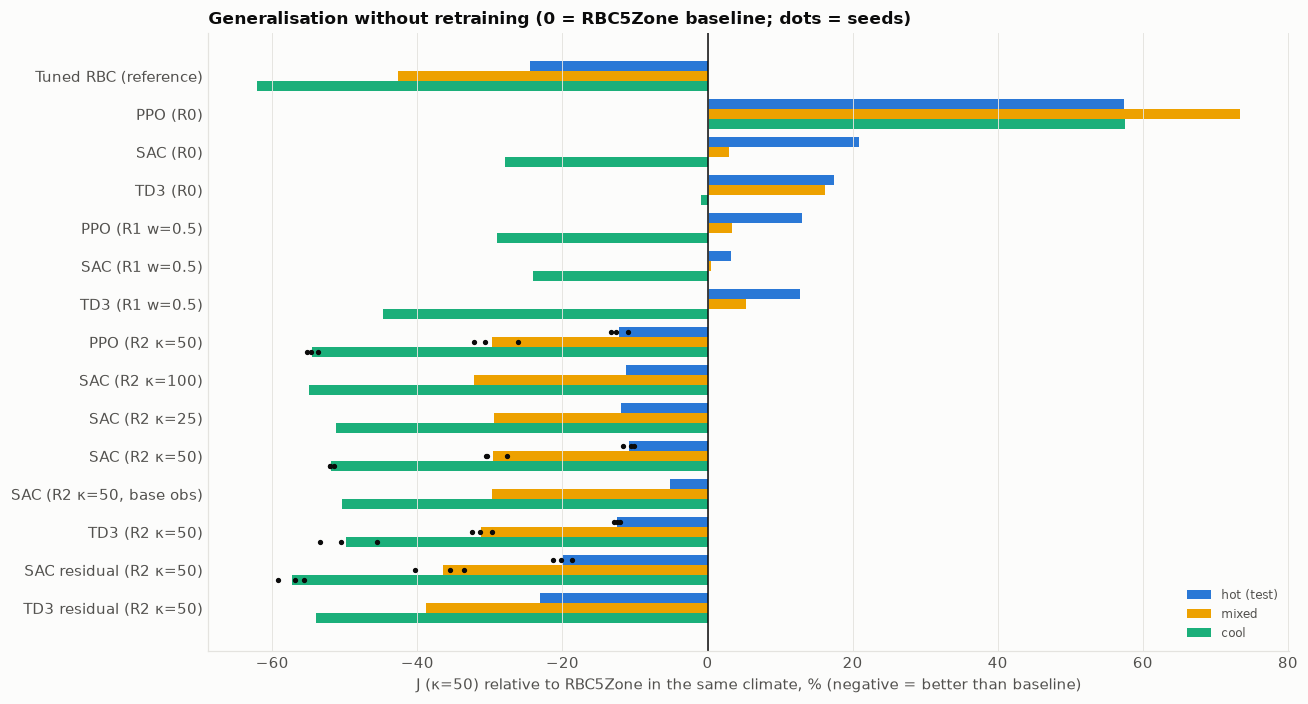

In [38]:
splits = {"test": "hot (test)", "stress_mixed": "mixed", "stress_cool": "cool"}
skip = [("baseline", "Fixed 21/24"), BASE_KEY]
idx = [i for i in summ["test"].index if i not in skip]
fig, ax = plt.subplots(figsize=(12, 6.5))
h = 0.26
for j, (split, lab) in enumerate(splits.items()):
    ref = summ[split].loc[BASE_KEY, "J_k50"]
    rel = 100 * (summ[split].loc[idx, "J_k50"] / ref - 1)
    y = np.arange(len(idx)) + (j - 1) * h
    ax.barh(y, rel, height=h, color=SERIES[[0, 3, 2][j]], label=lab)
    c = cmp[split]
    for yi, (_, name) in zip(y, idx):
        pts = 100 * (c.loc[c["controller"] == name, "J_k50"] / ref - 1)
        if len(pts) > 1:
            ax.scatter(pts, np.full(len(pts), yi), color=TEXT, s=6, zorder=3)
ax.axvline(0, color=TEXT, lw=1)
ax.set_yticks(np.arange(len(idx)), [n for _, n in idx])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set(xlabel="J (κ=50) relative to RBC5Zone in the same climate, % (negative = better than baseline)",
       title="Generalisation without retraining (0 = RBC5Zone baseline; dots = seeds)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()

**Without retraining, all R2 agents beat RBC5Zone by 29–39 % in the mixed climate and by 50–57 % in the cool one.** The learned behaviour, the setback in the empty building, transfers to other climates. R0 agents range from −28 % to +73 %.

### 6.3 Where the stress-climate discomfort comes from (cool climate)

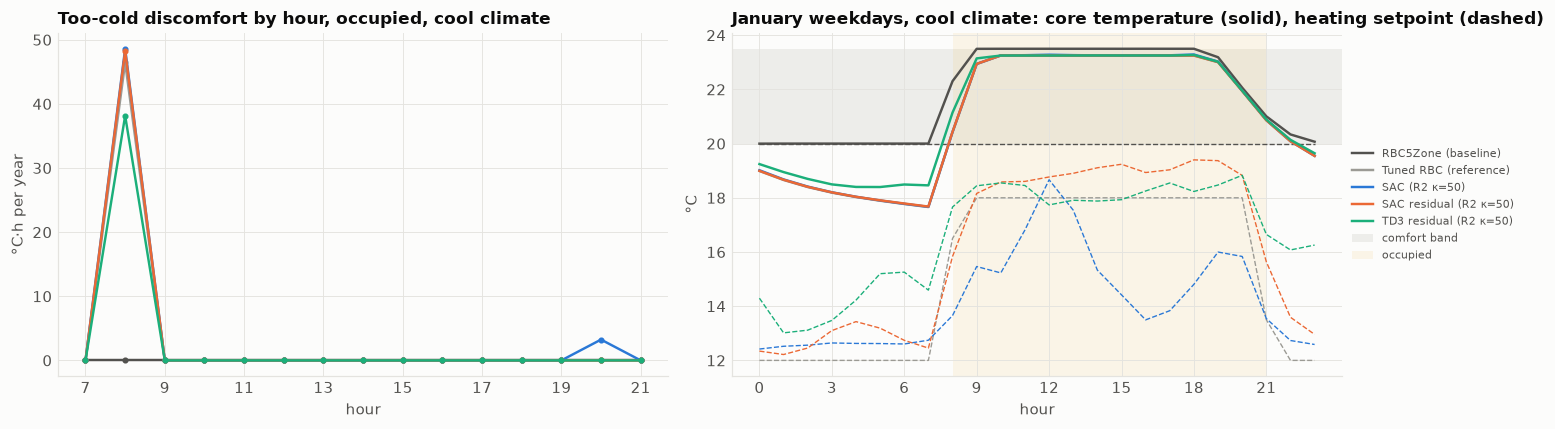

In [39]:
COOL = {"RBC5Zone (baseline)": base[("stress_cool", "rbc5zone")], "Tuned RBC (reference)": base[("stress_cool", "tuned_rbc_w0.5")],
        "SAC (R2 κ=50)": rv.load_eval_log("sac_r2_k50_s1", "stress_cool"),
        "SAC residual (R2 κ=50)": rv.load_eval_log("sac_res_k50_s1", "stress_cool"),
        "TD3 residual (R2 κ=50)": rv.load_eval_log("td3_res_k50_s1", "stress_cool")}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
for (lab, d), col in zip(COOL.items(), [TEXT_2, "#9b9a94", *SERIES]):
    lo, hi = comfort_bounds(d["month"])
    cold = (lo - d[zone_temp_col(CORE_ZONE)]).clip(lower=0) * STEP_HOURS * d["occupied"]
    ax1.plot(cold.groupby(d["hour"]).sum().loc[7:21], color=col, marker="o", ms=3, label=lab)
    wd = d[(d.month == 1) & (d.groupby(["month", "day_of_month"])["people_occupant"].transform("max") > 0)]
    ax2.plot(wd.groupby("hour")[zone_temp_col(CORE_ZONE)].mean(), color=col, label=lab)
    ax2.plot(wd.groupby("hour")["a_heat"].mean(), color=col, lw=0.9, ls="--")
ax2.axhspan(20, 23.5, color=GRID, alpha=0.6, lw=0, label="comfort band")
ax2.axvspan(8, 21, color=SERIES[3], alpha=0.08, lw=0, label="occupied")
ax1.set(xlabel="hour", ylabel="°C·h per year", xticks=range(7, 22, 2),
        title="Too-cold discomfort by hour, occupied, cool climate")
ax2.set(xlabel="hour", ylabel="°C", xticks=range(0, 24, 3),
        title="January weekdays, cool climate: core temperature (solid), heating setpoint (dashed)")
ax2.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()

In the cool climate almost all discomfort occurs at **08:00, the first occupied hour**, for the tuned RBC and the agents alike. After the night setback the building is still cold when people arrive. No controller pre-heats the building, because the hot training climate never required it.

## 7. Agent behaviour

This section examines what the agents actually do: setpoints and core temperature on typical days, the distribution of energy use, and the sources of the remaining errors.

### 7.1 Typical days on test: v2 agents

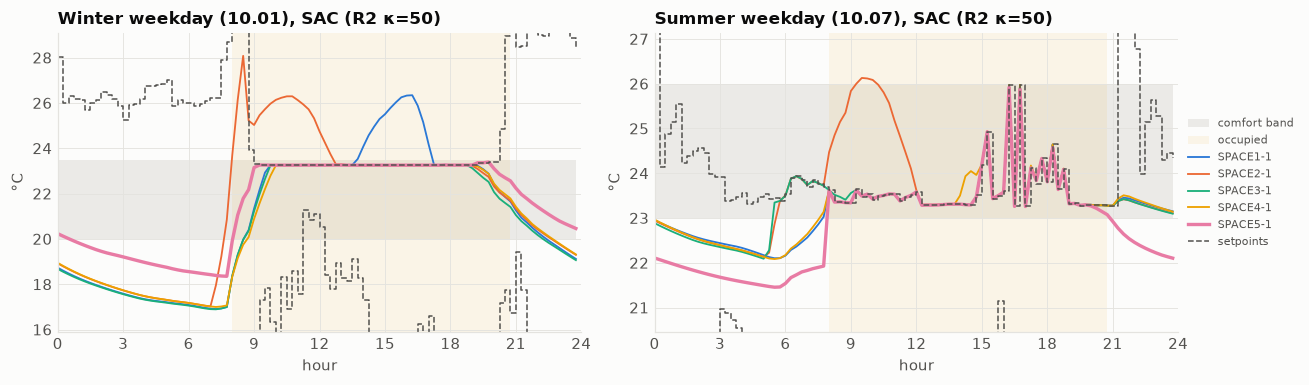

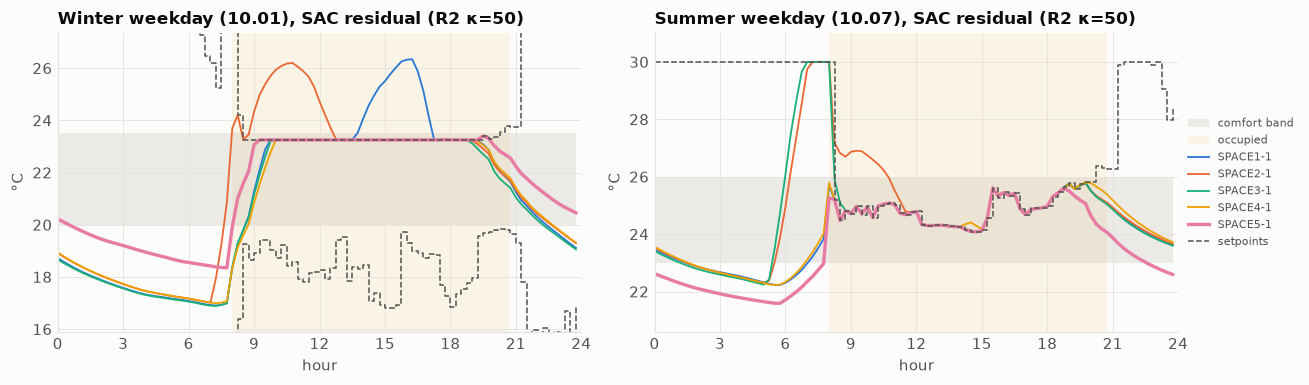

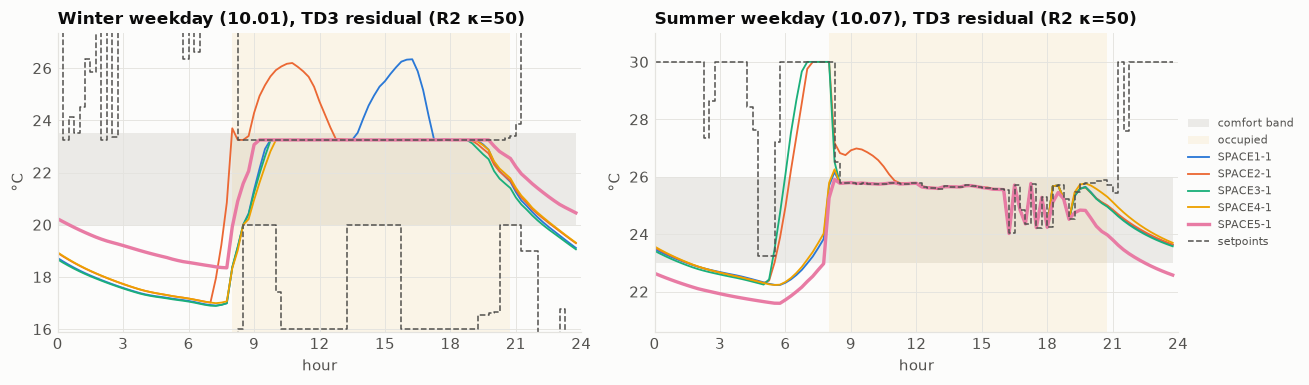

In [40]:
BEHAVIOUR = {"RBC5Zone (baseline)": base[("test", "rbc5zone")],
             "Tuned RBC (reference)": base[("test", "tuned_rbc_w0.5")],
             "SAC (R2 κ=50)": rv.load_eval_log("sac_r2_k50_s1", "test"),
             "PPO (R2 κ=50)": rv.load_eval_log("ppo_r2_k50_s1", "test"),
             "TD3 (R2 κ=50)": rv.load_eval_log("td3_r2_k50_s1", "test"),
             "SAC residual (R2 κ=50)": rv.load_eval_log("sac_res_k50_s1", "test"),
             "TD3 residual (R2 κ=50)": rv.load_eval_log("td3_res_k50_s1", "test")}
BEHAVIOUR_COLOR = dict(zip(BEHAVIOUR, [TEXT, "#9b9a94", SERIES[0], SERIES[1], SERIES[2], SERIES[4], SERIES[6]]))
for name in ["SAC (R2 κ=50)", "SAC residual (R2 κ=50)", "TD3 residual (R2 κ=50)"]:
    plot_days(BEHAVIOUR[name], name)

All agents lower their setpoints at night. The plain SAC changes its setpoints strongly from step to step, while the residual agents follow the tuned RBC schedule more closely.

### 7.2 Mean weekday setpoints and core temperature (test, seed 1)

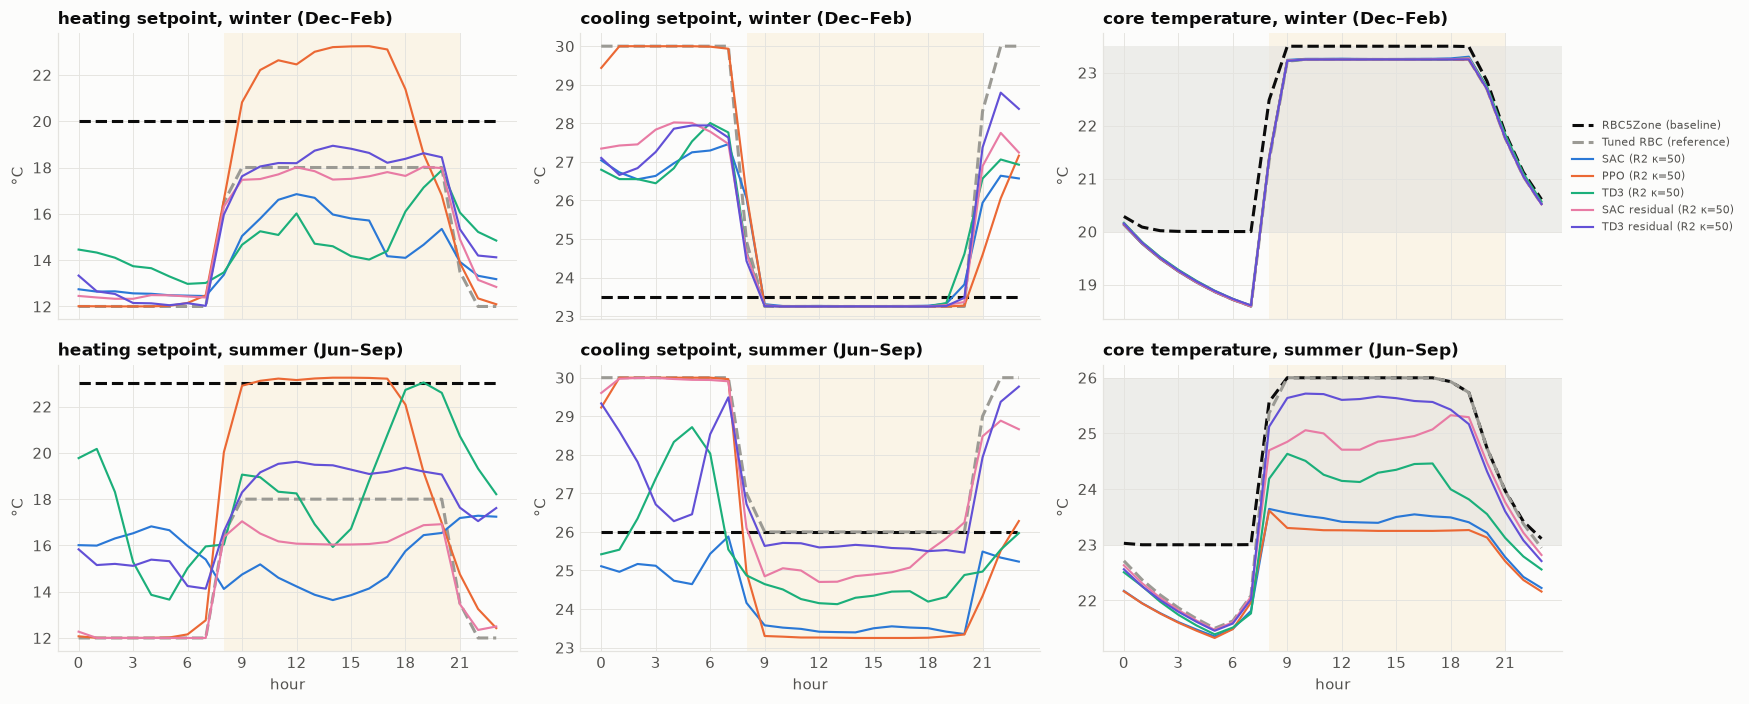

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5), sharex=True)
for row, (months, season) in enumerate([([12, 1, 2], "winter (Dec–Feb)"), ([6, 7, 8, 9], "summer (Jun–Sep)")]):
    for col, (var, name) in enumerate([("a_heat", "heating setpoint"), ("a_cool", "cooling setpoint"),
                                       ("air_temperature", "core temperature")]):
        ax = axes[row, col]
        ax.axvspan(8, 21, color=SERIES[3], alpha=0.08, lw=0)
        if var == "air_temperature":
            lo, hi = (20, 23.5) if row == 0 else (23, 26)
            ax.axhspan(lo, hi, color=GRID, alpha=0.6, lw=0)
        for lab, d in BEHAVIOUR.items():
            wd = d[d.month.isin(months) & (d.groupby(["month", "day_of_month"])["people_occupant"].transform("max") > 0)]
            ax.plot(wd.groupby("hour")[var].mean(), color=BEHAVIOUR_COLOR[lab], label=lab,
                    lw=2 if "RBC" in lab else 1.4, ls="--" if "RBC" in lab else "-")
        ax.set(title=f"{name}, {season}", ylabel="°C", xticks=range(0, 24, 3))
for ax in axes[1]:
    ax.set_xlabel("hour")
axes[0, 2].legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()

The curves average all weekdays of the season. In winter all agents follow the same pattern: low setpoints at night, warm-up at 08:00, core at about 23.3 °C. In summer, **plain agents cool the core to 23.3–24.2 °C although up to 26 °C is allowed**, while the tuned RBC and the residual agents stay near 25–26 °C.

### 7.3 Where the energy goes and how smooth the actions are (test, seed 1)

In [42]:
from hvac_rl.evaluate_v2 import behaviour

pd.DataFrame({lab: behaviour(d) for lab, d in BEHAVIOUR.items()}).T

,"mean |Δ heat sp|, °C/step","mean |Δ cool sp|, °C/step","heat sp unocc, °C","cool sp unocc, °C","T core occ, summer, °C","T core occ, winter, °C","E occupied, MWh","E weekday nights, MWh","E weekends, MWh","E Jun–Sep, MWh","E Oct–May, MWh"
RBC5Zone (baseline),1.71e-04,1.43e-04,21.01,24.34,25.84,23.37,10.94,4.54,3.26,7.08,11.67
Tuned RBC (reference),8.94e-02,8.71e-02,12.07,29.93,25.83,23.06,11.22,1.17,1.46,5.68,8.17
SAC (R2 κ=50),6.48e-01,2.80e-01,14.42,25.77,23.47,23.08,13.16,1.27,2.26,8.05,8.64
PPO (R2 κ=50),2.79e-01,1.43e-01,13.81,28.68,23.28,23.06,13.44,1.13,1.84,7.98,8.44
TD3 (R2 κ=50),9.35e-01,5.71e-01,15.72,26.84,24.21,23.07,12.65,1.66,1.90,7.50,8.71
SAC residual (R2 κ=50),4.07e-01,2.73e-01,13.00,28.40,24.91,23.06,11.92,1.19,1.49,6.38,8.22
TD3 residual (R2 κ=50),3.99e-01,3.13e-01,14.95,28.24,25.44,23.06,11.51,1.27,1.52,6.00,8.30


**The agents learned the night setback:** weekday-night energy is 1.1–1.7 MWh, against 4.5 MWh for RBC5Zone. **The remaining gap to the tuned RBC is summer overcooling**, +1.8–2.4 MWh in June–September for the plain agents. The setpoints also change by 0.1–0.9 °C every 15 minutes (tuned RBC: 0.09 °C), so the smoothness penalty is too weak.

### 7.4 Monthly energy and discomfort (test, seed 1)

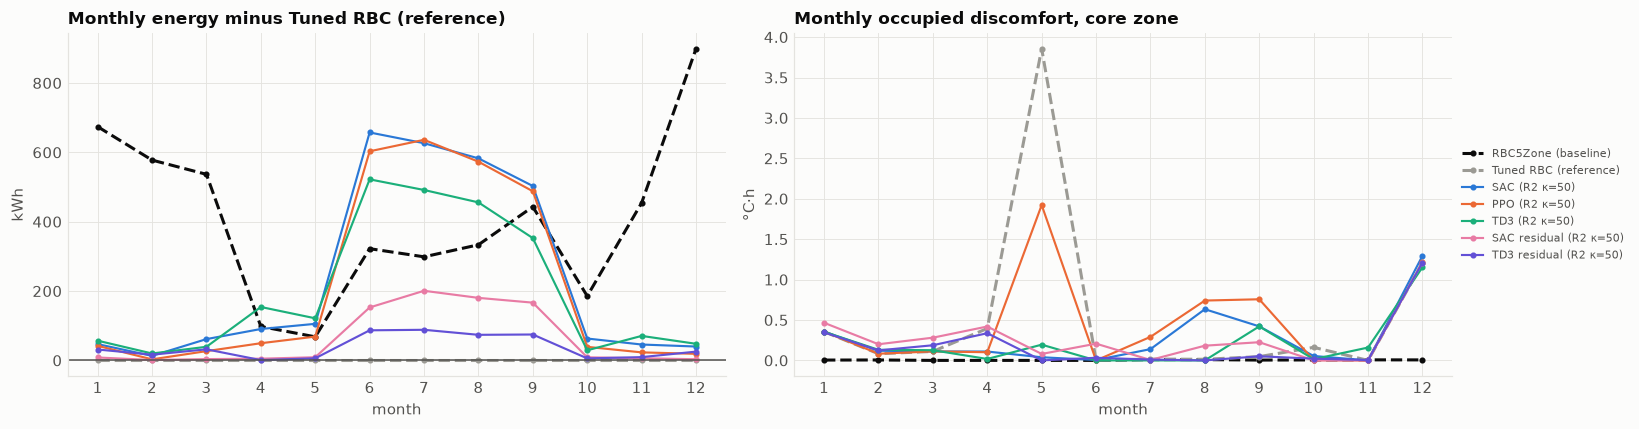

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))
ref = BEHAVIOUR["Tuned RBC (reference)"].groupby("month")["energy_kwh"].sum()
for lab, d in BEHAVIOUR.items():
    kw = dict(color=BEHAVIOUR_COLOR[lab], label=lab, lw=2 if "RBC" in lab else 1.4, ls="--" if "RBC" in lab else "-",
              marker="o", ms=3)
    ax1.plot(d.groupby("month")["energy_kwh"].sum() - ref, **kw)
    occ = d[d["occupied"]]
    ax2.plot((occ.groupby("month")[f"viol_{CORE_ZONE}"].sum() * STEP_HOURS).reindex(range(1, 13), fill_value=0), **kw)
ax1.axhline(0, color=TEXT_2, lw=1)
ax1.set(xlabel="month", ylabel="kWh", xticks=range(1, 13), title="Monthly energy minus Tuned RBC (reference)")
ax2.set(xlabel="month", ylabel="°C·h", xticks=range(1, 13), title="Monthly occupied discomfort, core zone")
ax2.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()

From October to May the agents stay within a few hundred kWh of the tuned RBC each month; **all the excess energy appears in June–September**.

### 7.5 Building snapshots: 3D geometry coloured by simulated zone temperature (test)

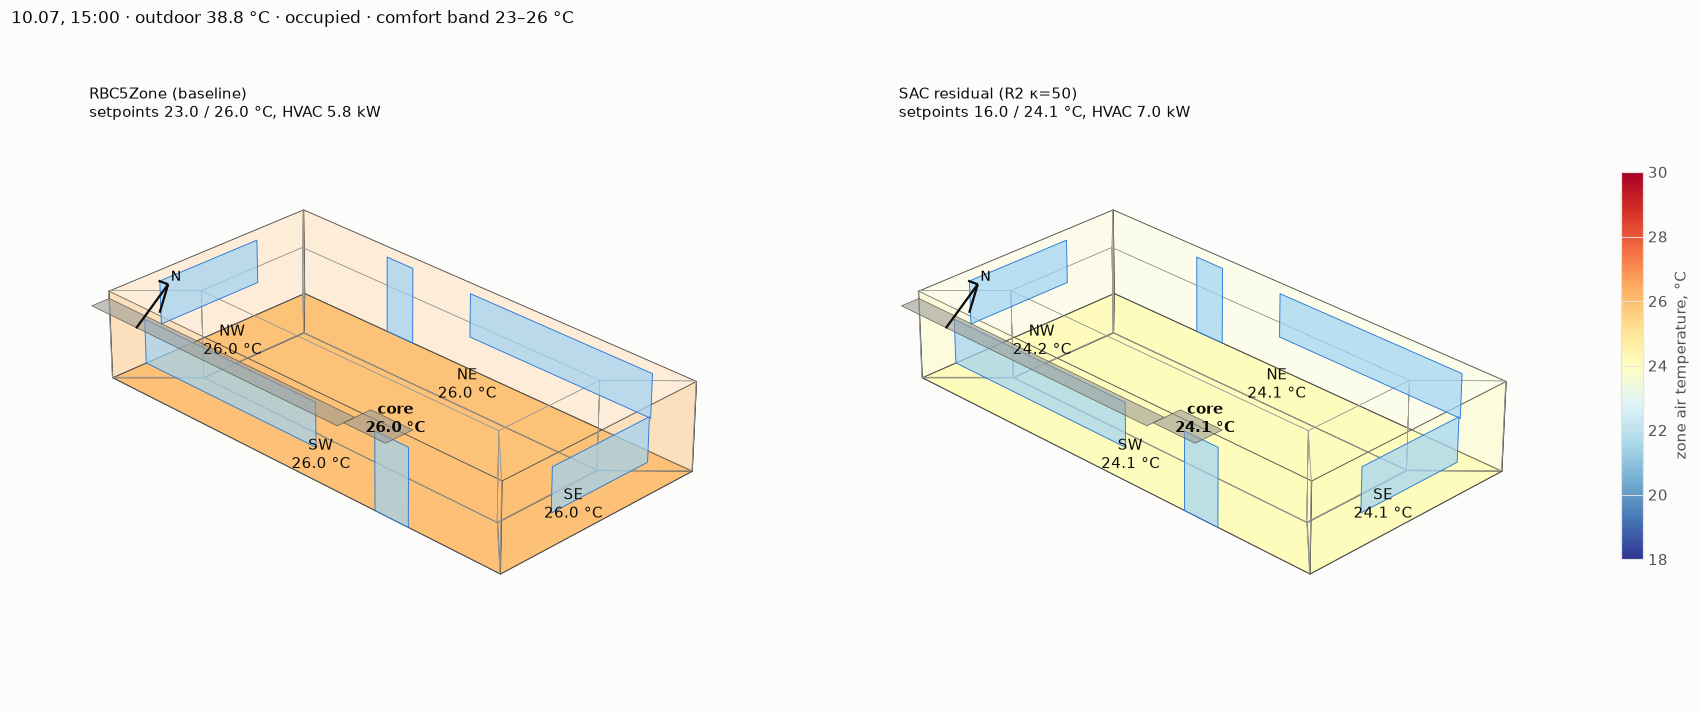

In [44]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

GEOM = building.geometry()
GEOM_XYZ = np.vstack(GEOM["vertices"])
TEMP_CMAP, TEMP_NORM = plt.get_cmap("RdYlBu_r"), plt.Normalize(18, 30)
ZONE_SHORT = dict(zip(ZONES, ["SW", "SE", "NE", "NW", "core"]))
SURFACE_STYLE = {"Window": dict(facecolor="#9fd3f5", edgecolor=SERIES[0], lw=0.6, alpha=0.7),
                 "Shading": dict(facecolor="#9b9a94", edgecolor=TEXT_2, lw=0.4, alpha=0.6)}


def draw_building(ax, row, label):
    temps = {z: row[zone_temp_col(z)] for z in ZONES}
    ax.computed_zorder = False
    for _, s in GEOM[GEOM["zone"].isin(ZONES)].iterrows():
        colour = TEMP_CMAP(TEMP_NORM(temps[s["zone"]]))
        if s["kind"] == "Floor":
            kw, z = dict(facecolor=colour, edgecolor=TEXT_2, lw=0.6, alpha=0.95), 1
        elif s["kind"] == "Wall":
            outdoor = s["boundary"] == "Outdoors"
            kw = (dict(facecolor=colour, edgecolor=TEXT_2, lw=0.6, alpha=0.25) if outdoor
                  else dict(facecolor="none", edgecolor="#9b9a94", lw=0.4))
            z = 2
        elif s["kind"] in SURFACE_STYLE:
            kw, z = SURFACE_STYLE[s["kind"]], 3
        else:
            continue
        ax.add_collection3d(Poly3DCollection([s["vertices"]], zorder=z, **kw))
    floors = GEOM[GEOM["kind"].eq("Floor") & GEOM["zone"].isin(ZONES)].set_index("zone")["vertices"]
    for zone, v in floors.items():
        c = v.mean(axis=0)
        ax.text(c[0], c[1], 0.1, f"{ZONE_SHORT[zone]}\n{temps[zone]:.1f} °C", ha="center", va="center", fontsize=10,
                zorder=10, color=TEXT, weight="bold" if zone == CORE_ZONE else "normal")
    x0, y1 = GEOM_XYZ[:, 0].min(), GEOM_XYZ[:, 1].max()
    ax.quiver(x0, y1 - 7, 0, 0, 6, 0, color=TEXT, lw=1.5, zorder=10)
    ax.text(x0, y1 - 0.5, 0, "N", fontsize=9, zorder=10)
    ax.set(xlim=(GEOM_XYZ[:, 0].min(), GEOM_XYZ[:, 0].max()), ylim=(GEOM_XYZ[:, 1].min(), y1), zlim=(0, 2.6))
    ax.set_box_aspect((np.ptp(GEOM_XYZ[:, 0]), np.ptp(GEOM_XYZ[:, 1]), 6), zoom=1.25)
    ax.view_init(elev=28, azim=-75)
    ax.set_axis_off()
    ax.text2D(0.04, 0.97, f"{label}\nsetpoints {row['a_heat']:.1f} / {row['a_cool']:.1f} °C, HVAC {row['power_kw']:.1f} kW",
              transform=ax.transAxes, fontsize=10, color=TEXT, va="top")


def building_frame(logs, month, day, hour, fig=None):
    fig = fig or plt.figure(figsize=(16, 6.4))
    fig.clear()
    rows = {}
    for k, (lab, d) in enumerate(logs.items()):
        rows[lab] = d[(d.month == month) & (d.day_of_month == day) & (d.hour == hour)].iloc[0]
        width = 0.92 / len(logs)
        draw_building(fig.add_axes([k * width, 0, width, 0.9], projection="3d"), rows[lab], lab)
    r = next(iter(rows.values()))
    lo, hi = comfort_bounds(r["month"])
    fig.suptitle(f"{day:02d}.{month:02d}, {hour:02.0f}:00 · outdoor {r['outdoor_temperature']:.1f} °C · "
                 f"{'occupied' if r['occupied'] else 'unoccupied'} · comfort band {lo:g}–{hi:g} °C",
                 x=0.02, ha="left", fontsize=11, color=TEXT)
    fig.colorbar(plt.cm.ScalarMappable(norm=TEMP_NORM, cmap=TEMP_CMAP), cax=fig.add_axes([0.935, 0.2, 0.012, 0.55]),
                 label="zone air temperature, °C")
    return fig


SNAPSHOT = {"RBC5Zone (baseline)": BEHAVIOUR["RBC5Zone (baseline)"],
            "SAC residual (R2 κ=50)": BEHAVIOUR["SAC residual (R2 κ=50)"]}
building_frame(SNAPSHOT, 7, 10, 15);

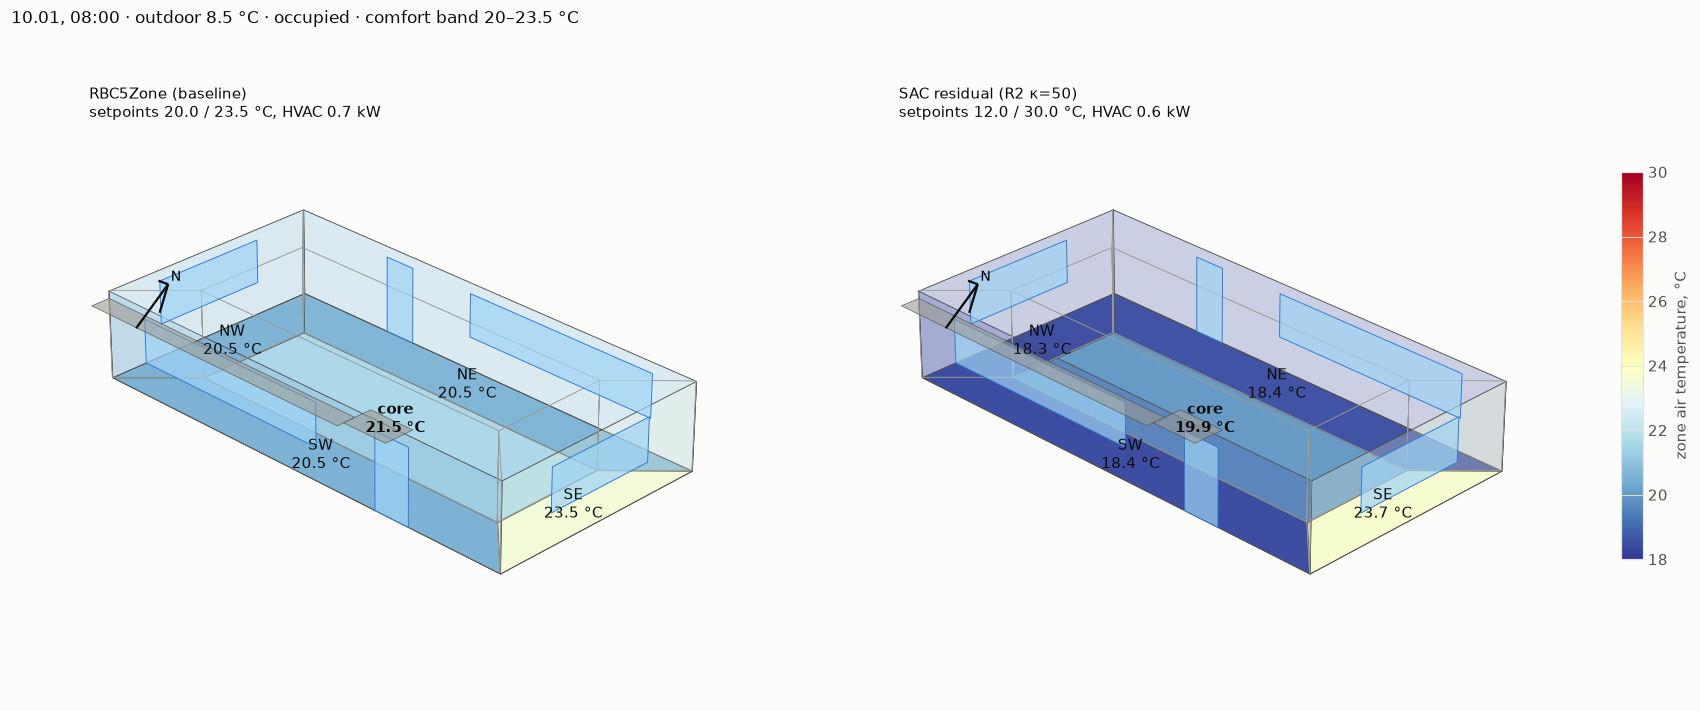

In [45]:
building_frame(SNAPSHOT, 1, 10, 8);

In [46]:
from pathlib import Path
from matplotlib.animation import FuncAnimation, PillowWriter

Path("figures").mkdir(exist_ok=True)
anim_fig = plt.figure(figsize=(16, 6.4))
anim = FuncAnimation(anim_fig, lambda h: building_frame(SNAPSHOT, 7, 10, h, anim_fig), frames=range(24))
anim.save("figures/building_summer_day.gif", writer=PillowWriter(fps=3), dpi=80)
plt.close(anim_fig)

![Summer weekday, hourly](figures/building_summer_day.gif)

The geometry is taken from the EnergyPlus model, and each zone is coloured by its simulated air temperature. On a summer afternoon the baseline holds 26 °C at 5.8 kW, while the agent holds 24.1 °C at 7.0 kW, which is the overcooling observed above. On a winter morning the night setback of the agent leaves the zones at 18–20 °C when people arrive, which explains its morning discomfort.

## 8. Conclusions and limitations

### Main results (test year, hot climate, vs the RBC5Zone baseline)

| Reward used for training | Energy | Occupied discomfort | J (κ = 50) |
|---|---|---|---|
| R0: Sinergym built-in | +10…+42 % | 28–56 °C·h | +17…+57 % |
| R1: first design, w = 0.5 | −12…−15 % | 56–105 °C·h | +3…+13 % |
| **R2: calibrated, κ = 50** | **−12…−14 %** | **3–4 °C·h** | **−11…−14 %** |
| **R2 + residual on tuned RBC** | **−21…−24 %** | **2–4 °C·h** | **−20…−23 %** |
| *Tuned RBC (reference)* | *−26 %* | *6 °C·h* | *−24 %* |

RBC5Zone: 18.7 MWh, 0.05 °C·h.

### Conclusions

1. **The reward determines the outcome more than the algorithm.** Replacing R0 with R2 reduced J by 25–45 % for every algorithm; under R2, SAC, PPO and TD3 differ by no more than 2 %.
2. **R0 is misaligned with the real goal.** It penalises discomfort in the empty building, so R0 agents never learn the night setback, and its ranking of controllers is unrelated to the KPI (ρ = −0.14).
3. **A reward needs an explicit price of comfort.** The weight w in R1 has no physical meaning, and w = 0.5 made comfort almost free (4.3 kWh per °C·h). R2 states the price in kWh per °C·h, and the reward and the KPI agree exactly (ρ = 1.0).
4. **No reward hacking is observed.** Despite the wide 12–30 °C range, R2 agents keep occupied discomfort at 2–6 °C·h a year and reach the limits of the range only when the building is empty.
5. **The structure of the agent matters more than the weight.** Comfort band and calendar in the observation: −5 % J. Residual actions: a further −12 %. Varying κ from 25 to 100 has no clear effect.
6. **Transfer to other climates.** Without retraining, R2 agents keep a 29–57 % advantage over RBC5Zone in the mixed and cool climates, but, like the tuned RBC, they do not pre-heat after the night setback.
7. **Remaining gap.** The tuned rule stays 2–18 % better in J. The agents overcool in summer (23.3–24.2 °C instead of up to 26 °C, about +2 MWh), and their setpoints are noisy. For this building, most of the achievable saving comes from the occupancy schedule, which a simple rule captures exactly.

### Limitations

- One building with one setpoint pair and core-zone comfort only; the perimeter overheats regardless of control.
- 3 seeds for the main R2 runs; the R0 and R1 agents, TD3 residual, the κ sweep and the observation ablation use 1 seed.
- Default SB3 hyperparameters; HVAC electricity only, without tariffs or peak charges.
- The tuned RBC benefits from a fully known, fixed occupancy schedule (weekdays 08–21, no holidays).

### Further work

Asymmetric comfort term against summer overcooling, a stronger smoothness penalty, training on several climates (to learn pre-heating), an MPC baseline, time-of-use tariffs.